# Deep-learning emulators of CMAQ daily mean surface NO<sub>2</sub> over the contiguous United States, 2015 to 2019

**Ehsan Nikfarjam**, Independent Researcher, ORCID iD [https://orcid.org/0009-0002-7423-2819](https://orcid.org/0009-0002-7423-2819)<br>
**Mohsen Nikfarjam**, Independent Researcher, ORCID iD [https://orcid.org/0009-0003-8753-3773](https://orcid.org/0009-0003-8753-3773)<br>
These authors contributed equally.

A walkthrough of the report dated 3 November 2026, which is not yet peer reviewed.

---

This notebook walks through the report: the question, the data, the splits and the models, and the evaluation. It reads the evaluation outputs deposited in `results/`, takes the report's key numbers from them and redraws the report's main figures with the deposited code in `report/`. No input data are needed except the NHGIS state boundaries for the maps (see the README). Every number below is the report's, each figure is the report's, redrawn, and the quoted passages keep the report's numbering of its sections, figures, tables and appendices.

## Key points

* This report describes two deep-learning emulators of CMAQ's daily mean surface nitrogen dioxide (NO<sub>2</sub>) on 53,594 land cells of the contiguous United States at 12 km, trained on the U.S. Environmental Protection Agency's EQUATES v1.0 data for 2015 to 2019.
* On the 1,687 test days, the main emulator, a residual U-Net that read CMAQ's weekday climatology (training-year average by date and weekday) and predicted CMAQ's departure from it, had a root mean square error (RMSE) of 0.501 parts per billion (ppb) and a correlation of 0.956 with CMAQ (means of five yearly values).
* Four comparisons fixed in advance, adjusted for multiple testing, favored it.
* Both emulators underestimated CMAQ's highest tenth of values on average in every year, partly because CMAQ's own values set that tenth.
* These results measure agreement with CMAQ in held-out years; agreement with observations, the response to changed emissions and speed against CMAQ remain untested.

---

## Contents

1. [The question and the design](#1-question)
2. [The data](#2-data)
3. [The splits and the models](#3-splits-models)
4. [The evaluation](#4-evaluation)
    * [4.1 The environment and the deposited outputs](#4-environment)
    * [4.2 The key numbers](#4-key-numbers)
    * [4.3 The figures of the report (Figures 1 to 9)](#4-figures)
5. [Limitations](#5-limitations)
6. [How to rerun each stage](#6-rerun)
7. [References](#7-references)

<a id="1-question" name="1-question"></a>

## 1. The question and the design

Chemical transport models such as the Community Multiscale Air Quality model (CMAQ) are costly; a fast emulator could let many more cases be examined.

For nitrogen dioxide (NO<sub>2</sub>) only, the analyses behind Figures 3 to 5 of Payami et al. (2025) were repeated on the Air QUAlity TimE Series (EQUATES) data of the U.S. Environmental Protection Agency (EPA) for 2015 to 2019. Payami et al. (2025) trained U-Nets (Ronneberger et al., 2015) on EQUATES to emulate the daily mean surface NO<sub>2</sub>, ozone and fine particulate matter of the Community Multiscale Air Quality model (CMAQ) over the contiguous United States (US), holding out one year at a time. They plotted emulated against simulated values (their Figure 3), the mean maps of 2016 (their Figure 4) and the daily series of 10 large cities (their Figure 5). An earlier U-Net emulator of CMAQ's hourly surface NO<sub>2</sub> over the contiguous US (Salman et al., 2024) simulated one hour in 10.5 s on one processor, against 71.75 min for CMAQ, also on one processor (their p. 10).

This report follows the evaluation design of Payami et al. (2025) and extends it with simpler models, comparisons specified in advance, held-back weeks and repeated trainings. Two emulators were trained on the same data and tested on the same held-out years and test days: a reference U-Net built like the published one, and a residual U-Net that predicts CMAQ's departure from a climatology of CMAQ fitted on the training years. Both were compared with simpler models (climatologies, regressions, gradient-boosted trees and a per-cell network), so that the gain from deep learning could be judged against what simpler tools already achieve. Four comparisons each had a margin, the smallest difference worth reporting (Section 3.3). A set of whole weeks was held back from training and evaluated once at the end, and the trainings with 2016 and with 2019 held out were repeated from several random starts to measure training randomness.

The data and the land cells of the grid are described in Section 2, and the emulators, the simpler models, the training and the evaluation in Section 3. Section 4 reports the results, from the daily agreement with CMAQ to the errors at the highest values and on cell-days with emissions outside the training range. Section 5 discusses them beside the values published by Payami et al. (2025), and Sections 6 and 7 give the limitations and the proposed next steps. The appendices hold the data versions, splits, settings and compute (A to D), further tables and figures (E and F), the exploratory comparisons (G) and the analyses fixed in advance (H).

The cells below read only this repository: the outputs of the two evaluations in `results/`, which the report's figures and tables were drawn from, and the figure scripts in `report/`.

<a id="2-data" name="2-data"></a>

## 2. The data

All inputs and the target came from EPA's EQUATES v1.0 data (U.S. EPA, 2021): CMAQ version 5.3.2 (U.S. EPA, 2020) simulations over the contiguous United States on EPA's 12 km grid (12US1), with the meteorology, made with the Weather Research and Forecasting model version 4.1.1 (Skamarock et al., 2019), and the emissions that CMAQ read (described for 2002 to 2017 by Foley et al., 2023). The data came from EPA's EQUATES pages and the Data Warehouse of the Community Modeling and Analysis System (CMAS), through three public routes (Appendix Table A1). EPA's Remote Sensing Information Gateway (RSIG) web service supplied CMAQ's hourly surface NO<sub>2</sub> and the surface and lowest-layer meteorological fields, aggregated on the server to daily means of the UTC day, and the boundary-layer height also to its daily maximum, for 2015 to 2019 and the last day of 2014, which the previous-day inputs need. EPA's local-day product of 2016 served as a check: on one summer day, 1 July 2016, over the grid's 137,241 cells, the mean absolute difference between EPA's local-day mean of surface NO<sub>2</sub> and the UTC-day mean was 0.098 parts per billion (ppb), and the mean difference, local-day minus UTC-day, was &minus;0.011 ppb. The public CMAS bucket on Amazon Web Services supplied the CMAQ-ready emissions of 2017 and 2019, their point-source stack files and 14 files of the Meteorology-Chemistry Interface Processor (MCIP) that describe the grid and the land surface. The emissions of 2015, 2016 and 2018 are published only on the CMAS Google Drive, from which they were taken.

The target is CMAQ's hourly-average surface NO<sub>2</sub>, that of its lowest model layer (about 19 m deep; U.S. EPA, 2021), as a 12 km cell mean in ppb, averaged over each UTC day, which runs from 19:00 the day before to 19:00 local standard time in the Eastern time zone and from 16:00 to 16:00 in the Pacific time zone. The inputs follow the 16 inputs of Payami et al. (2025, their Table S1) with two changes, besides the stand-ins listed in Appendix C: their two rainfall rates were taken as one precipitation channel, and the 10 m wind speed was added. They comprise nine meteorological fields (pressure, temperature, wind speed and the two wind components, solar radiation at the ground, water vapor, boundary-layer height and precipitation), three land-surface fields (terrain height, urban fraction and the dominant land-use class) and the gridded emissions of nitric oxide (NO), NO<sub>2</sub>, nitrous acid (HONO) and volatile organic compounds of each date. Where a variable was available only in another file, a close stand-in was used (for example, the lowest model layer's pressure for surface pressure). The two wind components, given at the cell corners of the lowest model layer, were averaged over each cell's four corners. The point and marine sources were added as one channel of nitrogen oxides (NO<sub>x</sub>; here and throughout, the sum of NO, NO<sub>2</sub> and HONO), each stack summed into its cell at the surface. For the three point sectors that EQUATES gives only on representative days, the mean of that year's days of the same weekday class in the month was used. Biogenic, lightning, residential wood combustion and fire emissions were not among the inputs, and plume rise was not represented. The residual U-Net also read five fields of the previous day (boundary-layer height, wind speed, the two wind components and temperature), the day's maximum boundary-layer height, and the weekday climatology of CMAQ.

The 12US1 grid has 299 rows and 459 columns of 12 km cells on a Lambert conformal projection; the maps draw each cell as its own quadrilateral in an equal-area projection (EPSG:5070). The emulators were trained and evaluated on its 53,594 land cells: the cells whose center lies inside the 48 contiguous states and the District of Columbia (Natural Earth's state boundaries at 1:10 million (admin-1) with large lakes removed, version 5.1.1) and that MCIP marks as land. Each city's point came from Natural Earth's populated places (version 5.1.2), and its series is the mean over the land cells of the 3 &times; 3 window of cells centered on the cell that holds the point (4 to 9 land cells).

The EQUATES data are public and in the public domain (U.S. EPA, 2021); EPA's data use policy requires that a copy of the policy accompany any copy of the data passed on. The policy is in `results/EQUATES_Data_Use_Policy.pdf`; it asks that published material cite the datasets (DOI 10.15139/S3/F2KJSK) and the emissions data (Foley et al., 2023); they are cited here as follows.

* U.S. Environmental Protection Agency (U.S. EPA) (2021). EQUATES CMAQv5.3.2 output (version 1.0) [data file and documentation]. <https://doi.org/10.15139/S3/F2KJSK>. Accessed 24 October 2026 through EPA's Remote Sensing Information Gateway and the CMAS Data Warehouse (Amazon Web Services, <https://registry.opendata.aws/cmas-data-warehouse>, and Google Drive).
* Foley, K. M., Pouliot, G. A., Eyth, A., Aldridge, M. F., Allen, C., Appel, K. W., Bash, J. O., Beardsley, M., Beidler, J., Choi, D., Farkas, C., Gilliam, R. C., Godfrey, J., Henderson, B. H., Hogrefe, C., Koplitz, S. N., Mason, R., Mathur, R., Misenis, C., Possiel, N., Pye, H. O. T., Reynolds, L., Roark, M., Roberts, S., Schwede, D. B., Seltzer, K. M., Sonntag, D., Talgo, K., Toro, C., Vukovich, J., Xing, J., Adams, E. (2023). 2002&ndash;2017 anthropogenic emissions data for air quality modeling over the United States. *Data in Brief* 47, 109022. <https://doi.org/10.1016/j.dib.2023.109022>

The land mask and the city points were made with Natural Earth, which is in the public domain. The state lines on the maps come from the 2010 TIGER/Line state boundaries of IPUMS NHGIS (Manson et al., 2024), used under the IPUMS terms; the boundary file is not part of this repository.

<a id="3-splits-models" name="3-splits-models"></a>

## 3. The splits and the models

Each of the five years was held out in turn (leave one year out), and the models of that fold were trained on the other four. The year 2019 is the forward fold, whose models saw only earlier years. Within the training years, the days of every fifth ISO week served as validation days, used only to choose the checkpoint and to stop training. Before any training, 112 days in 16 whole weeks spread over the seasons (21 days in each of 2015 to 2018 and 28 days in 2019) were set aside, with 27 buffer days beside them (the day before and after each block of held-back weeks and the last day of 2019). These days were removed from every training and validation set and used once, after the main evaluation, to repeat the four comparisons. The test days of each held-out year are the year less its held-back and buffer days: 338, 339, 338, 338 and 334 days for 2015 to 2019, 1,687 in all. No training read a test, held-back or buffer day. Appendix Figure A1 shows the five folds day by day.

Table 1 lists the models.

**Table 1.** The models compared, each trained on four years of modeled CMAQ NO<sub>2</sub> (ppb) and tested on the fifth, 2015 to 2019, contiguous US land cells.

| Model | What it is | Target and loss | Training |
|---|---|---|---|
| Residual U-Net (the main emulator) | U-Net with residual blocks and squeeze-and-excitation gates; 24 inputs: the reference U-Net's, five weather fields of the previous day, the daily maximum boundary-layer height and the weekday climatology | CMAQ minus the weekday climatology, scaled; squared error | 16,000 steps; seed 0 for every held-out year; more seeds for 2016 and 2019 |
| Reference U-Net | U-Net built like that of Payami et al. (2025); 17 inputs: their 16 weather, emission and land inputs (one rainfall channel for two, wind speed added) and a point- and marine-source NO<sub>x</sub> channel | CMAQ, scaled; one minus the index of agreement (as Salman et al., 2024) | 6,000 steps; seeds as above |
| Per-cell network | The residual U-Net's inputs and target with no spatial context (a network of 1 &times; 1 convolutions) | Same as the residual U-Net | 6,000 steps |
| Gradient-boosted trees | Histogram gradient boosting on 53 features of weather, emissions, land and the climatology | CMAQ minus the weekday climatology; squared error | 500 iterations, 255 leaves; fitted on a sample of land cells of each training day (Appendix C) |
| Linear model on tree features | Ridge regression on the trees' 53 features | Same as the trees | One fit |
| Weather regression | Ridge regression for each cell on 14 meteorological predictors | Log ratio of CMAQ to the weekday climatology | One fit per cell |
| Weekday climatology | Each cell's smoothed day-of-year value (a 61-day triangular window) times its weekday factor | None (a fixed value for each cell and date) | Fitted on the training years |
| Emission-scaled climatology | The weekday climatology times the day's NO<sub>x</sub> emissions over their climatology, in a 9 &times; 9-cell window | None | Fitted on the training years |
| Cell mean | Each cell's mean over the training days | None | Fitted on the training years |

Input counts are numbers of input channels; training steps are optimizer steps. Every model was fitted on training days only; the weekday climatology of the held-out year was fitted on all four training years. Exploratory networks: Appendix G.

The reference U-Net followed the published network (two strided downsamplings, skip connections, batch normalization and rectified linear unit activations), with 17 inputs (the 16 inputs of the published model with a point- and marine-source NO<sub>x</sub> channel added) and the scaled CMAQ value as its target. The published paper states neither its loss nor its number of training steps; it gives a training time of about 400 minutes (p. 13). Here the reference U-Net took the loss of the earlier emulator of Salman et al. (2024, p. 4), one minus the index of agreement (Appendix Equation (8)), and was trained for 6,000 steps, fewer than the 100 epochs in batches of 64 of that study would give. The residual U-Net used a deeper network with residual blocks (He et al., 2016) and squeeze-and-excitation gates (Hu et al., 2018), and 24 inputs (those of the reference U-Net, five weather fields of the previous day (Section 2.2), the daily maximum boundary-layer height and the weekday climatology of the day). Its target was CMAQ minus the weekday climatology, scaled, and it was trained with a squared-error loss (Appendix Equation (8)) for 16,000 steps. The residual U-Net thus differs from the reference U-Net in its network, inputs and their scale, target, loss and training length, and in its tile rule, the number of a training tile's cells that the loss had to score: at least one, against at least a quarter of them for the reference U-Net (Section 3.2). The weekday climatology (a smoothed day-of-year value of CMAQ for each cell, times a weekday factor) was fitted on the training years only. Because the residual U-Net reads this climatology and adds its prediction to it, it emulates CMAQ's departure from CMAQ's own climatology of the training years, and it needs CMAQ runs of those years; the reference U-Net reads no field derived from CMAQ's concentrations. The name residual U-Net refers to this target; its network also has residual blocks. For cell $i$ and day $t$, the weekday climatology in ppb is

$$
\begin{gathered} \begin{array}{cc} \hspace{0.75em} \displaystyle C _{i,t} = \max\bigl(0, \hspace{0.2778em} S _i(\phi _t) \thinspace \rho _i(w _t)\bigr), \hspace{0.75em} & \hspace{0.75em} \displaystyle S _i(\phi) = \frac{\sum _{u\in F} K(\phi,\phi _u) \thinspace o _{i,u}}{\sum _{u\in F} K(\phi,\phi _u)}, \hspace{0.75em} \cr \hspace{0.75em} \displaystyle \overset{\rule{0pt}{0.17em}}{K(\phi,\phi') = \max\Bigl(0, \hspace{0.2778em} 1-\frac{\mathop{\mathrm{dist}}(\phi,\phi')}{31}\Bigr),} \hspace{0.75em} & \hspace{0.75em} \displaystyle \overset{\rule{0pt}{0.17em}}{\rho _i(w) = \frac{\sum _{u\in F : \thinspace w _u=w} o _{i,u}}{\sum _{u\in F : \thinspace w _u=w} S _i(\phi _u)},} \hspace{0.75em} \end{array} \cr \overset{\rule{0pt}{0.31em}}{\mathop{\mathrm{dist}}(\phi,\phi') = \min\bigl(|\phi-\phi'|, \hspace{0.2778em} 366-|\phi-\phi'|\bigr),} \end{gathered}
$$

where $o _{i,u}$ is CMAQ's value in ppb on day $u$, $F$ is the set of training days the climatology is fitted on, $\phi _t$ is the position of day $t$ in a 366-day calendar, $w _t$ is its weekday, $S _i$ is the smoothed day-of-year value, $K$ is its weight at calendar distance $\mathop{\mathrm{dist}}$, and $\rho _i(w)$ is the weekday factor, which is 1 where its denominator is under 10<sup>&minus;6</sup> ppb. Every sum runs over days within one cell.

The baselines were fitted on the same training days and evaluated on the same test days. The weekday climatology is the reference of every skill score (Section 3.3). The cell mean, the emission-scaled climatology, a per-cell weather regression, gradient-boosted trees on 53 features and a linear model on the same features cover the range from the simplest reference to a flexible statistical model. The per-cell network had the residual U-Net's inputs and target but no spatial context, and was trained for 6,000 steps. Some results also include exploratory networks (Appendix G). They are the intermediate networks between the two U-Nets, a reference U-Net with 19 inputs adapted from the 18 of Salman et al. (2024), a residual U-Net that read climatological emissions in place of each date's own, networks trained on a single year and two five-seed ensembles, each the mean of five networks' predictions. Persistence of CMAQ's previous day was not used as a baseline, because an emulator run without CMAQ does not have that value.

The design of Payami et al. (2025) was followed with these departures. Six of their 16 inputs were replaced by the nearest fields that the RSIG service supplies and their two rainfall rates by one precipitation channel (Appendix C); the 10 m wind speed was added, and so was a point- and marine-source NO<sub>x</sub> channel, because those sources come in stack files apart from the gridded emissions (Section 2.1). The residual U-Net also reads CMAQ's weekday climatology, which their input rule leaves out (Section 5). The test days leave out the 139 held-back and buffer days. Where the paper is silent, the choices were made here: daily means of the UTC day, scores over the land cells of Section 2.3, training tiles at random positions, and validation on whole ISO weeks of the training years, so that most validation days are not next to training days.

The equations of the evaluation, as the evaluation code computes them (`pipeline/8_evaluation/eval/metrics.py`), with $e$ a model's value and $o$ CMAQ's value on a cell-day, $C$ the weekday climatology, $\bar{o}$ CMAQ's mean, $n$ the number of cell-days and the sums over the pooled cell-days of a held-out year:

* the residual U-Net's target, before scaling: $o - C$, CMAQ minus the weekday climatology;
* the root mean square error: $\mathrm{RMSE} = \sqrt{\sum (e - o)^2 / n}$;
* the skill score against the weekday climatology: $\mathrm{SS} = 1 - \mathrm{MSE}(\mathrm{model}) / \mathrm{MSE}(\mathrm{climatology})$, one minus the ratio of the model's mean squared error to that of the weekday climatology, so a model that adds nothing to the climatology scores zero;
* the index of agreement: $\mathrm{IOA} = 1 - \sum (e - o)^2 / \sum (|e - \bar{o}| + |o - \bar{o}|)^2$.

<a id="4-evaluation" name="4-evaluation"></a>

## 4. The evaluation

The emulators were judged against CMAQ on the test days of the year each model had not seen. The descriptive statistics follow the formulas of Payami et al. (2025): the Pearson correlation $R$, the index of agreement (IOA), the mean absolute error (MAE), the mean error (ME, emulator minus CMAQ) and the root mean square error (RMSE), each pooled over a year's cell-days. The five-year value of a statistic is the mean of its five yearly values. In the formulas below, $e _{i,t}$ is a model's value and $o _{i,t}$ CMAQ's value, both in ppb, on land cell $i$ (the set of land cells is $I$) and test day $t$ (the $n _y$ test days of held-out year $y$ are $T _y$); $\varepsilon _{i,t}=e _{i,t}-o _{i,t}$, $N _y=|I| \thinspace n _y$, and each sum runs over $i\in I$ and $t\in T _y$. The yearly statistics (with the normalized mean bias and error, NMB and NME, and $R^2$, all given in Appendix E) and the five-year value are

$$
\begin{gathered} \begin{array}{ccc} \hspace{0.75em} \displaystyle \mathrm{ME} _y = \frac{\sum \varepsilon _{i,t}}{N _y}, \hspace{0.75em} & \hspace{0.75em} \displaystyle \mathrm{MAE} _y = \frac{\sum |\varepsilon _{i,t}|}{N _y}, \hspace{0.75em} & \hspace{0.75em} \displaystyle \mathrm{RMSE} _y = \sqrt{\frac{\sum \varepsilon _{i,t}^2}{N _y}}, \hspace{0.75em} \cr \hspace{0.75em} \displaystyle \overset{\rule{0pt}{0.17em}}{\mathrm{NMB} _y = \frac{\sum \varepsilon _{i,t}}{\sum o _{i,t}},} \hspace{0.75em} & \hspace{0.75em} \displaystyle \overset{\rule{0pt}{0.17em}}{\mathrm{NME} _y = \frac{\sum |\varepsilon _{i,t}|}{\sum o _{i,t}},} \hspace{0.75em} & \hspace{0.75em} \displaystyle \overset{\rule{0pt}{0.17em}}{R^2 _y = 1-\frac{\sum \varepsilon _{i,t}^2}{\sum (o _{i,t}-\bar{o} _y)^2},} \hspace{0.75em} \end{array} \cr \overset{\rule{0pt}{0.31em}}{R _y = \frac{\sum (e _{i,t}-\bar{e} _y)(o _{i,t}-\bar{o} _y)}{\sqrt{\sum (e _{i,t}-\bar{e} _y)^2 \thinspace \sum (o _{i,t}-\bar{o} _y)^2}},} \cr \overset{\rule{0pt}{0.31em}}{\mathrm{IOA} _y = 1-\frac{\sum \varepsilon _{i,t}^2}{\sum \bigl(|e _{i,t}-\bar{o} _y|+|o _{i,t}-\bar{o} _y|\bigr)^2},} \cr \overset{\rule{0pt}{0.31em}}{\mathrm{cRMSE} _y = \sqrt{\frac{\sum (\varepsilon _{i,t}-\mathrm{ME} _y)^2}{N _y}} = \sqrt{\mathrm{RMSE} _y^2-\mathrm{ME} _y^2},} \cr \overset{\rule{0pt}{0.31em}}{\bar{\Theta} = \frac{1}{5}\sum _{y}\Theta _y,} \end{gathered} \tag{3}
$$

where $\bar{e} _y$ and $\bar{o} _y$ are the means over the year's cell-days, $R^2 _y$ is the coefficient of determination, which differs from the square of $R _y$, $\mathrm{cRMSE} _y$ is the centered RMSE, the RMSE of the errors about their mean, and $\bar{\Theta}$ is the five-year value of a yearly statistic $\Theta _y$. The square root in the RMSE is taken within each year, before the mean over years. ME, MAE, RMSE and cRMSE are in ppb; NMB, NME, $R$, IOA and $R^2$ have no unit. The skill score (SS) is one minus the ratio of a model's mean squared error to that of the weekday climatology, so a model that adds nothing to the climatology scores zero.

<a id="4-environment" name="4-environment"></a>

### 4.1 The environment and the deposited outputs

In Google Colab the first cell below fetches this repository; elsewhere it does nothing. The second lists the software, including NumPy (Harris et al., 2020) and Matplotlib (Hunter, 2007), checks every deposited output against its recorded sha256, and defines two helpers: one runs a figure script of `report/`, and one shows the figure it drew with its alternative text as the output's plain text.

In [1]:
# @title In Google Colab only: fetch this repository
import os
import subprocess
import sys

if "google.colab" in sys.modules and not os.path.exists("results/SHA256SUMS.txt"):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/Research-Portfolios/CMAQ-NO2-Emulator-Benchmark.git"], check=True)
    os.chdir("CMAQ-NO2-Emulator-Benchmark")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "pyshp==3.1.6"], check=True)

In [2]:
# @title 4.1 The environment and the deposited outputs
import base64
import contextlib
import hashlib
import io
import json
import platform
import runpy
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import numpy as np
import PIL
import pyproj
import shapefile
import shapely
from IPython.display import display
from PIL import Image as PILImage

REPO = Path.cwd()
RESULTS = REPO / "results"
FIRST = RESULTS / "evaluation_test_years"
SECOND = RESULTS / "evaluation_held_back"
BUILD = REPO / "build" / "figures"
sys.path.insert(0, str(REPO / "report"))

for name, version in [("Python", platform.python_version()),
                      ("NumPy", np.__version__),
                      ("Matplotlib", matplotlib.__version__),
                      ("pyproj", pyproj.__version__),
                      ("Shapely", shapely.__version__),
                      ("pyshp", shapefile.__version__),
                      ("Pillow", PIL.__version__)]:
    print(f"{name:<11}{version}")

# every deposited file against results/SHA256SUMS.txt
listed = matched = 0
for line in (RESULTS / "SHA256SUMS.txt").read_text().splitlines():
    if not line.strip() or line.startswith("#"):
        continue
    digest, name = line.split(maxsplit=1)
    name = name.lstrip("*")
    path = RESULTS / name if (RESULTS / name).exists() else REPO / name
    listed += 1
    matched += hashlib.sha256(path.read_bytes()).hexdigest() == digest
print(f"\nDeposited files checked against SHA256SUMS.txt: {matched} of {listed} match")
assert matched == listed


def run_builder(script):
    """Run one figure script of report/; its printed output is captured
    and not shown."""
    sink = io.StringIO()
    argv = sys.argv
    sys.argv = [script]  # as on the command line, with no arguments
    try:
        with contextlib.redirect_stdout(sink), contextlib.redirect_stderr(sink):
            runpy.run_path(str(REPO / "report" / script), run_name="__main__")
    except SystemExit as stop:
        if stop.code not in (None, 0):
            raise
    finally:
        sys.argv = argv


DEPOSITED = REPO / "figures"
MAPS = BUILD


def show_figure(stem, alt, width=1600, folder=None):
    """Show a figure, scaled with Pillow to about 1,600 pixels wide, with
    its alternative text as the output's plain text."""
    image = PILImage.open((folder or BUILD) / f"{stem}.png")
    if image.width > width:
        image = image.resize((width, round(image.height * width / image.width)),
                             PILImage.LANCZOS)
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    data = base64.b64encode(buffer.getvalue()).decode("ascii")
    bundle = {"image/png": data, "text/plain": alt}
    display(bundle, raw=True)

Python     3.13.5
NumPy      2.4.2
Matplotlib 3.11.1
pyproj     3.7.2
Shapely    2.1.2
pyshp      3.1.6
Pillow     12.3.0



Deposited files checked against SHA256SUMS.txt: 539 of 539 match


<a id="4-key-numbers" name="4-key-numbers"></a>

### 4.2 The key numbers

Each value below is read from the deposited outputs, or counted from them, and shown as the report prints it, in five groups. RMSE, R, the index of agreement and the skill score are means of the five yearly values, with the networks trained at seed 0; the four comparisons are those fixed in advance (C-1, the residual U-Net's skill score against the weekday climatology; C-2 to C-4, the RMSE of the gradient-boosted trees, of the reference U-Net and of the climatology's yearly mean map, each minus the residual U-Net's), with their intervals at the levels of Holm's procedure; the held-back days carry unadjusted 95 percent intervals.

In [3]:
# @title 4.2 The key numbers, read from the deposited outputs
def load(folder, name):
    return json.loads((folder / name).read_text())


metrics = load(FIRST, "metrics.json")["rows"]
five_fold = load(FIRST, "five_fold.json")["rows"]
family = load(FIRST, "family.json")
held_back = load(SECOND, "family.json")["lockbox"]

# the land cells and the test and held-back days
land_cells = next(r["cells"] for r in metrics
                  if r["model"] == "M" and r["seed"] == 0 and r["fold"] == 2016
                  and r["stratum_kind"] == "all")
test_days = {d["year"]: d["n_days"] for d in family["five_fold"]["draws"]}
held_back_days = {d["year"]: d["n_days"] for d in held_back["draws"]}
block_days = family["five_fold"]["draws"][0]["block"]

# the means of the five yearly values (networks at seed 0)
five = {r["model"]: r for r in five_fold
        if r["seed"] in (0, None) and r["model"] in ("M", "P", "GBT", "CLIM-WD")}
yearly_rmse_m = {r["fold"]: r["RMSE"] for r in metrics
                 if r["model"] == "M" and r["seed"] == 0
                 and r["stratum_kind"] == "all"}

# the four comparisons on the test days and on the held-back days
comp = family["five_fold"]["rows"]
held = held_back["rows"]


def fmt(value, kind):
    if kind == "int":
        return f"{int(value):,}"
    if kind == "lev":
        return f"{100 * value:.2f}".rstrip("0").rstrip(".")
    return f"{value:.{int(kind)}f}"


TABLE = [
    ("Land cells of the 12 km grid evaluated", land_cells, "int"),
    ("Test days of the five held-out years", sum(test_days.values()), "int"),
    ("Test days, 2015", test_days[2015], "int"),
    ("Test days, 2016", test_days[2016], "int"),
    ("Test days, 2017", test_days[2017], "int"),
    ("Test days, 2018", test_days[2018], "int"),
    ("Test days, 2019", test_days[2019], "int"),
    ("Held-back days", sum(held_back_days.values()), "int"),
    ("Residual U-Net, RMSE (ppb)", five['M']['RMSE'], "3"),
    ("Residual U-Net, correlation R", five['M']['R'], "3"),
    ("Residual U-Net, index of agreement", five['M']['IOA'], "3"),
    ("Residual U-Net, skill score", five['M']['SS'], "3"),
    ("Residual U-Net, lowest yearly RMSE (ppb)", min(yearly_rmse_m.values()), "3"),
    ("Residual U-Net, highest yearly RMSE (ppb)", max(yearly_rmse_m.values()), "3"),
    ("Reference U-Net, RMSE (ppb)", five['P']['RMSE'], "3"),
    ("Gradient-boosted trees, RMSE (ppb)", five['GBT']['RMSE'], "3"),
    ("Weekday climatology, RMSE (ppb)", five['CLIM-WD']['RMSE'], "3"),
    ("Resamples of the test days", comp['C-1']['n_resamples'], "int"),
    ("Days in each resampling block", block_days, "int"),
    ("Margin of C-2 to C-4 (ppb)", comp['C-2']['margin'], "2"),
    ("C-1, skill score", comp['C-1']['point'], "3"),
    ("C-1, interval level (percent)", comp['C-1']['level'], "lev"),
    ("C-1, interval lower end", comp['C-1']['lo'], "3"),
    ("C-1, interval upper end", comp['C-1']['hi'], "3"),
    ("C-1, median anomaly correlation", comp['C-1']['acc_median_five_fold'], "3"),
    ("C-2, RMSE difference (ppb)", comp['C-2']['point'], "3"),
    ("C-2, interval level (percent)", comp['C-2']['level'], "lev"),
    ("C-2, interval lower end (ppb)", comp['C-2']['lo'], "3"),
    ("C-2, interval upper end (ppb)", comp['C-2']['hi'], "3"),
    ("C-3, RMSE difference (ppb)", comp['C-3']['point'], "3"),
    ("C-3, interval level (percent)", comp['C-3']['level'], "lev"),
    ("C-3, interval lower end (ppb)", comp['C-3']['lo'], "3"),
    ("C-3, interval upper end (ppb)", comp['C-3']['hi'], "3"),
    ("C-4, map RMSE difference (ppb)", comp['C-4']['point'], "3"),
    ("C-4, interval level (percent)", comp['C-4']['level'], "lev"),
    ("C-4, interval lower end (ppb)", comp['C-4']['lo'], "3"),
    ("C-4, interval upper end (ppb)", comp['C-4']['hi'], "3"),
    ("Held-back days, C-1 skill score", held['C-1']['point'], "3"),
    ("Held-back days, C-1 lower end (95 percent)", held['C-1']['lo'], "3"),
    ("Held-back days, C-1 upper end (95 percent)", held['C-1']['hi'], "3"),
    ("Held-back days, C-3 (ppb)", held['C-3']['point'], "3"),
    ("Held-back days, C-3 lower end (ppb, 95 percent)", held['C-3']['lo'], "3"),
    ("Held-back days, C-3 upper end (ppb, 95 percent)", held['C-3']['hi'], "3"),
]

# the groups of rows, in order: (heading, number of rows)
GROUPS = [
    ("The data and the splits", 8),
    ("The residual U-Net", 6),
    ("The other models", 3),
    ("The four comparisons on the test days", 20),
    ("The held-back days", 6),
]

# one Markdown table per group, with a plain-text twin
width = max(len(label) for label, _, _ in TABLE)
plain = [f"{'Quantity':<{width}} | Value", "-" * width + "-|-" + "-" * 8]
markdown = []
start = 0
for heading, count in GROUPS:
    markdown += [f"| {heading} | Value |", "|---|---:|"]
    for label, value, kind in TABLE[start:start + count]:
        markdown.append(f"| {label} | {fmt(value, kind)} |")
        plain.append(f"{label:<{width}} | {fmt(value, kind)}")
    markdown.append("")
    start += count
assert start == len(TABLE)
display({"text/markdown": "\n".join(markdown),
         "text/plain": "\n".join(plain)}, raw=True)

| The data and the splits | Value |
|---|---:|
| Land cells of the 12 km grid evaluated | 53,594 |
| Test days of the five held-out years | 1,687 |
| Test days, 2015 | 338 |
| Test days, 2016 | 339 |
| Test days, 2017 | 338 |
| Test days, 2018 | 338 |
| Test days, 2019 | 334 |
| Held-back days | 112 |

| The residual U-Net | Value |
|---|---:|
| Residual U-Net, RMSE (ppb) | 0.501 |
| Residual U-Net, correlation R | 0.956 |
| Residual U-Net, index of agreement | 0.976 |
| Residual U-Net, skill score | 0.763 |
| Residual U-Net, lowest yearly RMSE (ppb) | 0.450 |
| Residual U-Net, highest yearly RMSE (ppb) | 0.588 |

| The other models | Value |
|---|---:|
| Reference U-Net, RMSE (ppb) | 0.575 |
| Gradient-boosted trees, RMSE (ppb) | 0.601 |
| Weekday climatology, RMSE (ppb) | 1.030 |

| The four comparisons on the test days | Value |
|---|---:|
| Resamples of the test days | 10,000 |
| Days in each resampling block | 7 |
| Margin of C-2 to C-4 (ppb) | 0.05 |
| C-1, skill score | 0.763 |
| C-1, interval level (percent) | 98.75 |
| C-1, interval lower end | 0.752 |
| C-1, interval upper end | 0.771 |
| C-1, median anomaly correlation | 0.813 |
| C-2, RMSE difference (ppb) | 0.100 |
| C-2, interval level (percent) | 98.33 |
| C-2, interval lower end (ppb) | 0.095 |
| C-2, interval upper end (ppb) | 0.105 |
| C-3, RMSE difference (ppb) | 0.074 |
| C-3, interval level (percent) | 97.5 |
| C-3, interval lower end (ppb) | 0.071 |
| C-3, interval upper end (ppb) | 0.076 |
| C-4, map RMSE difference (ppb) | 0.129 |
| C-4, interval level (percent) | 95 |
| C-4, interval lower end (ppb) | 0.117 |
| C-4, interval upper end (ppb) | 0.152 |

| The held-back days | Value |
|---|---:|
| Held-back days, C-1 skill score | 0.759 |
| Held-back days, C-1 lower end (95 percent) | 0.724 |
| Held-back days, C-1 upper end (95 percent) | 0.774 |
| Held-back days, C-3 (ppb) | 0.085 |
| Held-back days, C-3 lower end (ppb, 95 percent) | 0.075 |
| Held-back days, C-3 upper end (ppb, 95 percent) | 0.092 |


<a id="4-figures" name="4-figures"></a>

### 4.3 The figures of the report

Each figure below is drawn by the report's own figure script from the deposited outputs into `build/figures/` and shown with its alternative text as the output's plain text. The report's caption follows each figure, then the report's sentences on it and a folded text description of the figure.

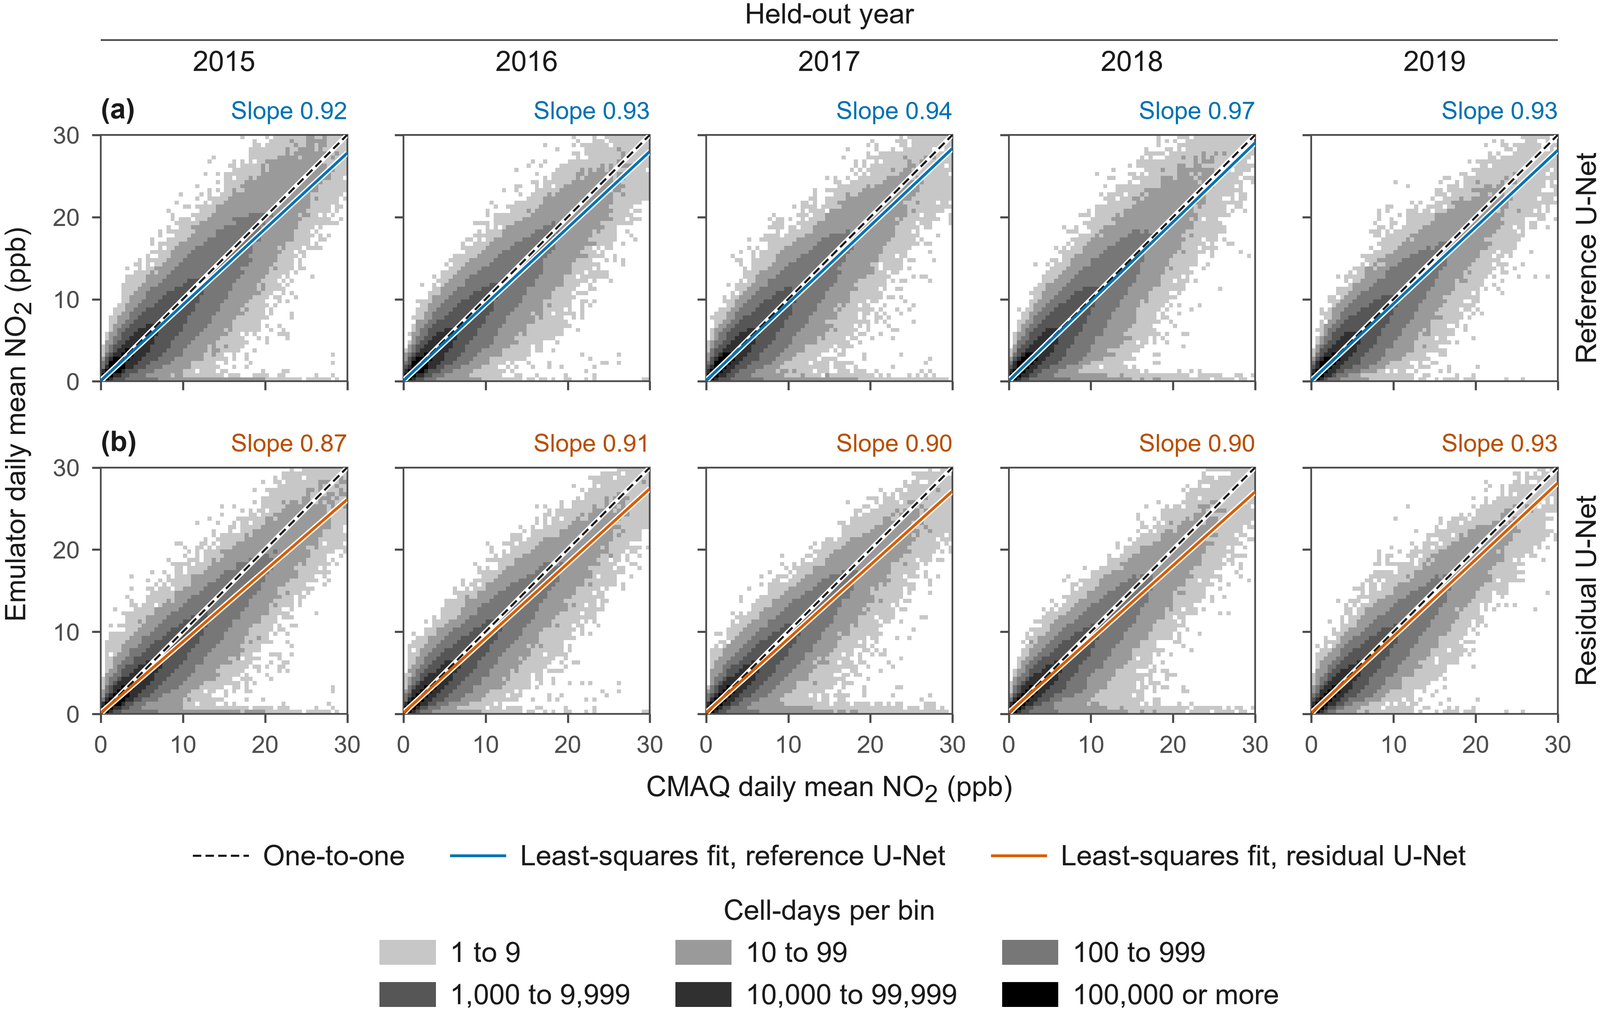

In [4]:
# @title Figure 1: The two U-Nets against CMAQ, cell-day by cell-day
run_builder("build_fig_F1.py")
alt = ("Ten binned scatter plots of emulator against CMAQ daily mean"
       " NO2 for two U-Nets and five held-out years, to judge "
       "agreement.")
show_figure("fig_F1", alt)

**Figure 1.** Modeled daily mean NO<sub>2</sub> (ppb) of the two U-Net emulators against CMAQ, contiguous US land cells of the 12 km grid, test days of the held-out years 2015 to 2019. Columns are held-out years; rows show (a) the reference and (b) the residual U-Net, both at seed 0. Each square is a 0.5 by 0.5 ppb bin shaded by its cell-day count in six classes (key); white bins hold none. Each solid line is a least-squares fit of the emulator on CMAQ to all stored bins, 0 to 100 ppb (bin centers weighted by counts), not to exact cell-day values, with its slope above the panel. Both axes run from 0 to 30 ppb; 5,051 of the 180,826,156 cell-days of the 10 panels (0.003 percent) have a CMAQ or emulator value at or above 30 ppb and are not drawn (at most 1,290 in one panel, reference U-Net, 2015). Table 2 gives the metrics.

The residual U-Net's points lie in a narrower band about the one-to-one line than the reference U-Net's, consistent with its lower RMSE. Its fitted slopes, 0.87 to 0.93, were at or below those of the reference U-Net, 0.92 to 0.97, in every year. Over the five held-out years its RMSE ranged from 0.450 to 0.588 ppb and its index of agreement from 0.975 to 0.979; the reference U-Net's RMSE ranged from 0.522 to 0.646 ppb.

<details>
<summary>Text description of Figure 1</summary>

Figure of ten square panels in two rows and five columns. Column heads over the top row, under one spanning head Held-out year: 2015, 2016, 2017, 2018, 2019. Row heads at the right edge of each row, read upward: Reference U-Net (top row, tagged (a) at its top-left), Residual U-Net (bottom row, tagged (b)). Horizontal axis label, shared: CMAQ daily mean NO2 (ppb), tick labels on the bottom row. Vertical axis label, shared: Emulator daily mean NO2 (ppb), tick labels on the left column. Both axes of every panel have ticks 0, 10, 20, 30. Each panel shows gray square bins of 0.5 ppb whose shade gives the count of cell-days, a dashed black one-to-one line on a thin white band from 0 to 30 ppb, and a solid least-squares line fitted to the binned values, blue in the top row and vermilion in the bottom row, also on a thin white band. Above each panel's upper right corner its slope is printed: Reference U-Net 2015, 0.92; Reference U-Net 2016, 0.93; Reference U-Net 2017, 0.94; Reference U-Net 2018, 0.97; Reference U-Net 2019, 0.93; Residual U-Net 2015, 0.87; Residual U-Net 2016, 0.91; Residual U-Net 2017, 0.90; Residual U-Net 2018, 0.90; Residual U-Net 2019, 0.93. A line key directly under the axis label names the dashed line One-to-one and the solid lines Least-squares fit, reference U-Net and Least-squares fit, residual U-Net. Under it, a key titled Cell-days per bin has six gray swatches from light to black: 1 to 9, 10 to 99, 100 to 999, 1,000 to 9,999, 10,000 to 99,999, 100,000 or more.

</details>

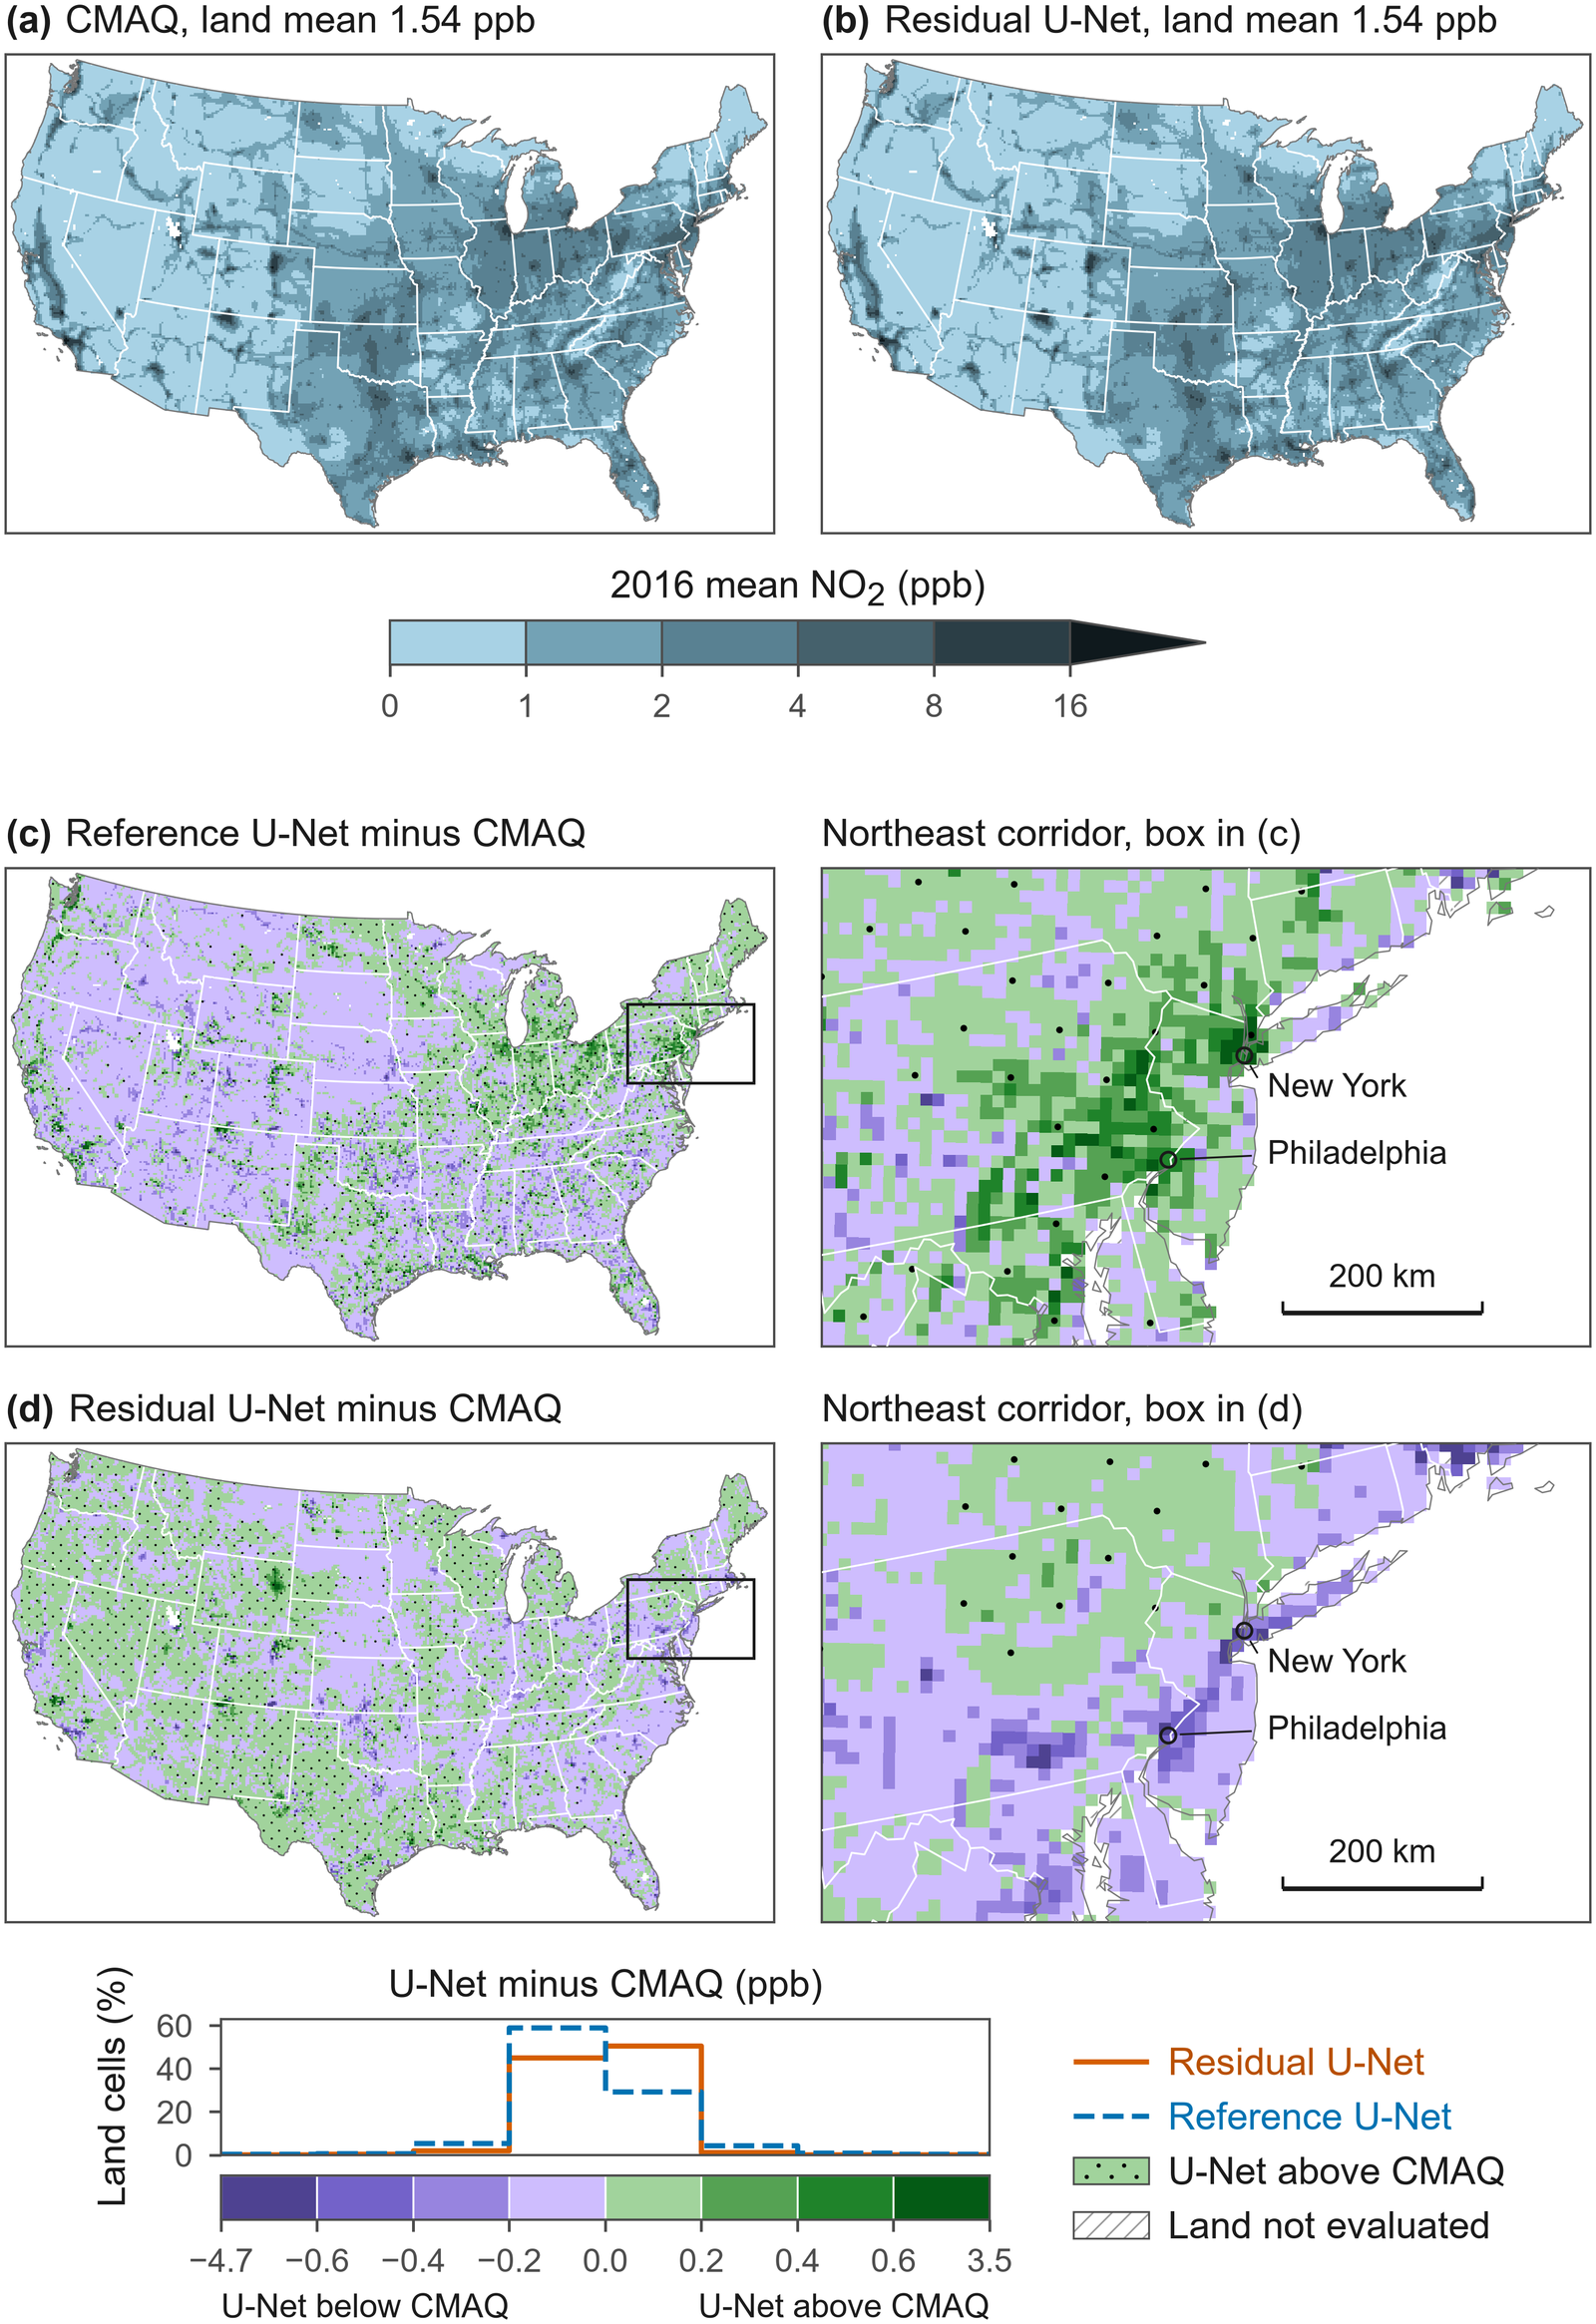

In [5]:
# @title Figure 2: Mean NO2 over the 2016 test days, CMAQ and emulators
try:
    run_builder("build_fig_maps.py")  # draws Figures 2, 9 and A3
    MAPS = BUILD
except SystemExit as stop:
    print(stop)
    print("The deposited map figures are shown instead.")
    MAPS = DEPOSITED
alt = ("US maps of 2016 mean NO2 from CMAQ and the residual U-Net, "
       "and each U-Net minus CMAQ in purple and green, with insets.")
show_figure("fig_F2", alt, folder=MAPS)

**Figure 2.** Modeled mean surface NO<sub>2</sub> (ppb) over the 339 test days of 2016, CMAQ and two emulators, contiguous US land cells of the 12 km grid, 2016 held out. (a) CMAQ and (b) the residual U-Net in six blue classes of doubling width (breaks 1 to 16 ppb). (c) The reference and (d) the residual U-Net minus CMAQ in steps of 0.2 ppb, purple below CMAQ and green above; outer classes run beyond &plusmn;0.6 ppb. Insets enlarge the boxed Northeast corridor; open circles mark cities. The lines over the color bar give each class's share of land cells. Dots mark the cells above CMAQ, the rarer sign over the figure's difference maps. Hatching marks the 85 cells of US land not evaluated, and white marks water and land outside the US; white lines are state boundaries and the gray line the coast and national borders. The maps use an equal-area projection.

Both emulators kept CMAQ's spatial pattern of mean NO<sub>2</sub> (Figure 2); Figures 2a and 2b follow Figure 4 of Payami et al. (2025). Over the 2016 test days, the correlation of the residual U-Net's mean map with CMAQ's was 0.997, and the RMSE of its mean map over cells 0.112 ppb, against 0.994 and 0.153 ppb for the reference U-Net.

<details>
<summary>Text description of Figure 2</summary>

Top row: two maps of the contiguous United States in an equal-area projection, (a) CMAQ and (b) the residual U-Net, mean surface NO2 over the 2016 test days in six classes of one blue hue from pale (under 1 ppb) to dark (16 ppb or more), each title giving the land mean (1.54 ppb for both); a horizontal key under them has breaks at 1, 2, 4, 8 and 16 ppb and a pointed open end. Middle and bottom rows: (c) the reference U-Net minus CMAQ and (d) the residual U-Net minus CMAQ, in four purple classes (below CMAQ) and four green classes (above CMAQ), steps of 0.2 ppb; dots mark the cells where the emulator is above CMAQ. A box on each map marks the Northeast corridor, enlarged at its right with a 200 km scale bar; in each inset small open circles mark New York and Philadelphia, each named beside it or joined to its name by a thin line. Under the maps, one key names the classes, with the lowest and highest differences, -4.7 and 3.5 ppb, at its ends and, above it, the share of land cells in each class as a solid vermilion line (residual U-Net) and a dashed blue line (reference U-Net); entries name the dots and the hatch. Hatching marks the 85 cells of US land not evaluated; white lines are state boundaries and a gray line the coast and national borders; water and land outside the US are white.

</details>

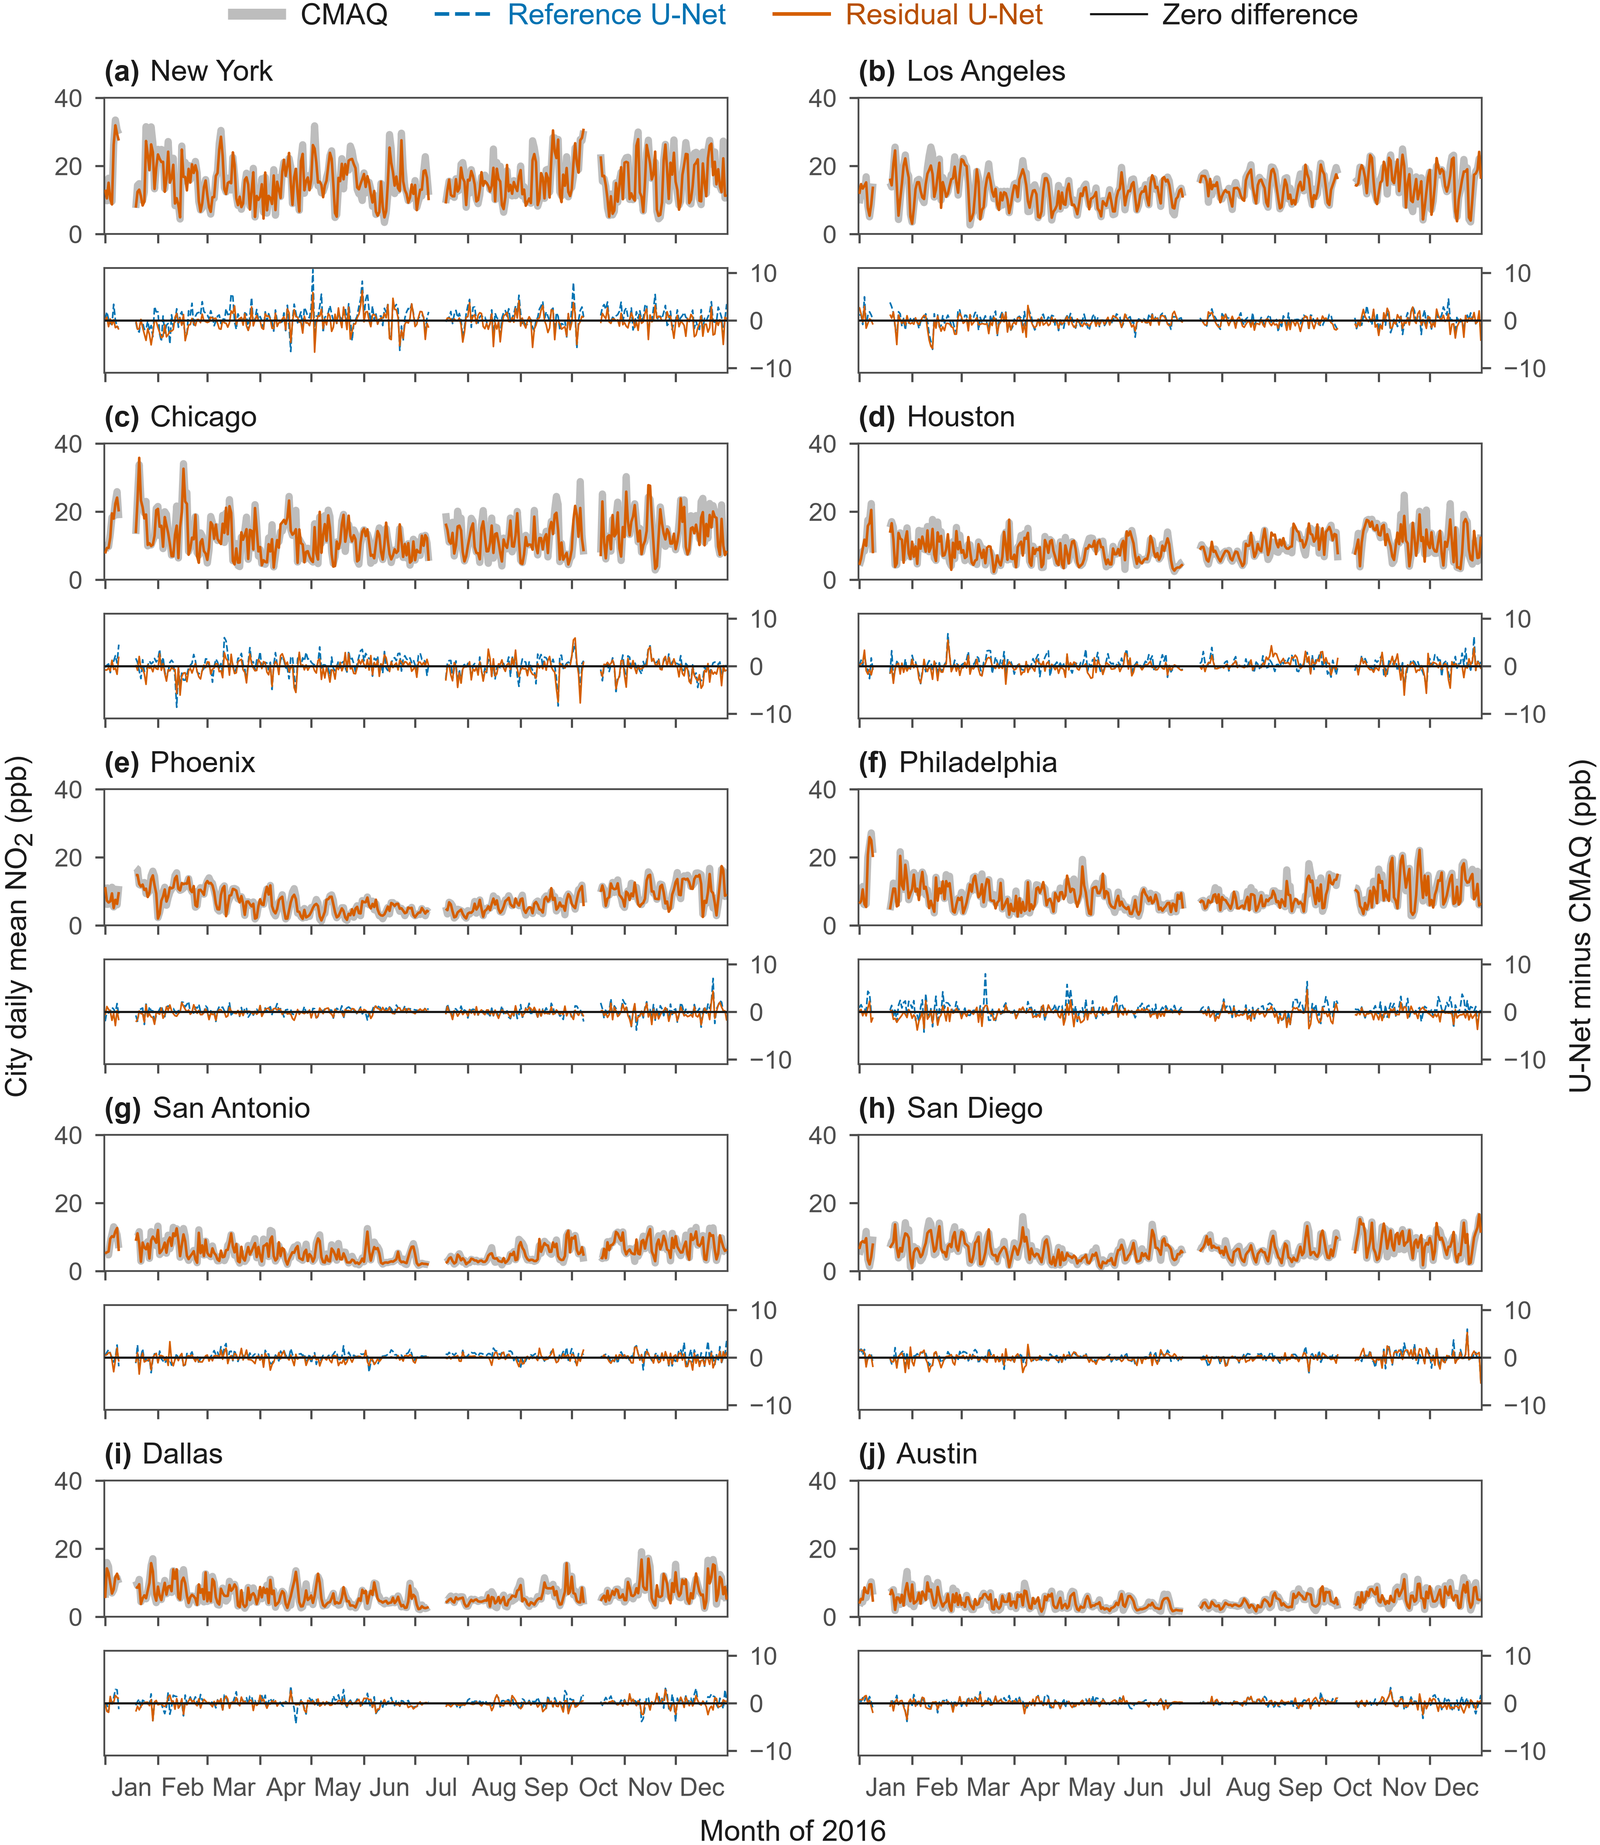

In [6]:
# @title Figure 3: Daily mean NO2 in ten large US cities, 2016
run_builder("build_fig_F3.py")
alt = ("Ten city panels of 2016 daily NO2, CMAQ and the residual "
       "U-Net, with strips of each U-Net minus CMAQ.")
show_figure("fig_F3", alt)

**Figure 3.** Modeled daily mean NO<sub>2</sub> (ppb) of CMAQ and the residual U-Net in 10 large US cities, and each U-Net minus CMAQ, on the 339 test days of 2016. Each series is the daily mean over the land cells of the 3 &times; 3 window of 12 km cells centered on the cell that holds the city's point (4 to 9 cells per city); both U-Nets are the networks trained with seed 0 without 2016. In each of (a) to (j), the upper plot shows CMAQ (wide light gray line) and the residual U-Net (vermilion line) on the scale at left. The strip below shows each U-Net minus CMAQ on the scale at right, the reference U-Net as a blue dashed line and the residual U-Net as a vermilion solid line. The black line marks zero difference. Gaps mark the 27 held-back and buffer days, and ticks mark month starts. Appendix Table A3 gives each city's $R$, IOA and errors. The difference strips were not specified in advance.

In the 10 large cities of Figure 5 of Payami et al. (2025), the residual U-Net followed CMAQ's day-to-day changes through 2016, including the winter peaks and the summer lows (Figure 3; the mean errors by city in Figure 4). The residual U-Net's correlation with CMAQ ranged from 0.940 in Houston to 0.970 in Phoenix, and its RMSE from 0.719 ppb in Austin to 1.892 ppb in New York (Appendix Table A3, Appendix Figure A4).

<details>
<summary>Text description of Figure 3</summary>

Figure of ten city panel pairs in five rows and two columns. Key above, centered: CMAQ (wide light gray line), Reference U-Net (blue dashed line), Residual U-Net (vermilion solid line), Zero difference (black line). City panels: (a) New York, (b) Los Angeles, (c) Chicago, (d) Houston, (e) Phoenix, (f) Philadelphia, (g) San Antonio, (h) San Diego, (i) Dallas, (j) Austin. Each has an upper plot with CMAQ and the residual U-Net, vertical ticks 0, 20, 40 at the left, and a strip below with each U-Net minus CMAQ about a black zero line, vertical ticks minus 10, 0, 10 at the right. Gaps in each series mark the 27 held-back and buffer days; ticks mark month starts. One title at the far left, City daily mean NO2 (ppb), and one at the far right, U-Net minus CMAQ (ppb), each centered on the ten panel pairs. Month names under the bottom strips; axis label Month of 2016.

</details>

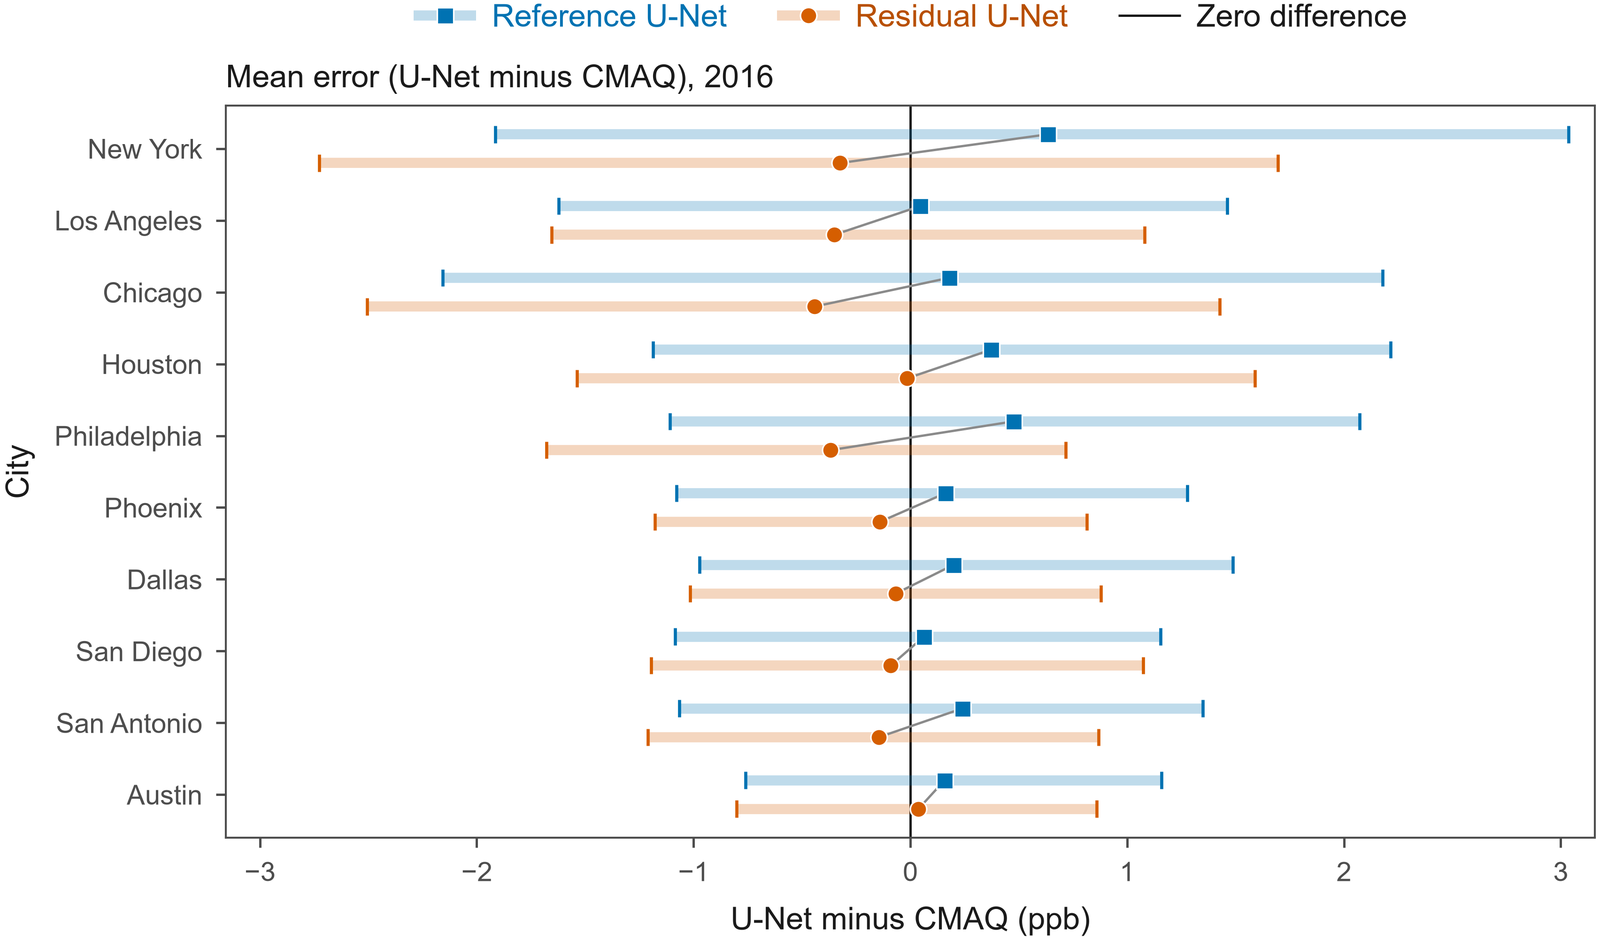

In [7]:
# @title Figure 4: Mean error of each U-Net in ten large US cities, 2016
run_builder("build_fig_F3k.py")
alt = ("Ten city rows of each U-Net's 2016 mean error against CMAQ, "
       "on pale 10th to 90th percentile bars of the daily "
       "differences.")
show_figure("fig_F3k", alt)

**Figure 4.** Mean error (ME) of each U-Net against CMAQ in modeled daily mean NO<sub>2</sub> (ppb), 10 large US cities, 339 test days of 2016. The city series are those of Figure 3, and both U-Nets are the networks trained with seed 0 without 2016. In each city row, a square marks the reference U-Net's ME, the mean over the test days of its daily differences from CMAQ (U-Net minus CMAQ), and a disc marks the residual U-Net's; a gray line joins the two. Each mark sits on a pale bar of its color that spans the 10th to the 90th percentile of those daily differences, with a tick at each end, and the black line marks zero difference. Rows run from the city with the highest CMAQ mean NO<sub>2</sub> (top) to the lowest; Appendix Table A3 gives each U-Net's mean error by city. These results are descriptive and were not specified in advance.

On average over the test days the reference U-Net was above CMAQ in every city and the residual U-Net below it in nine of the 10 (Figure 4; Appendix Table A3). The city errors were larger than the RMSE over all cell-days of 2016 (0.491 ppb), consistent with CMAQ's higher and more variable NO<sub>2</sub> in cities.

<details>
<summary>Text description of Figure 4</summary>

Figure of one panel. Key above, centered: Reference U-Net (pale blue bar, square), Residual U-Net (pale vermilion bar, disc), Zero difference (black line). Title: Mean error (U-Net minus CMAQ), 2016. One row per city, highest CMAQ mean first; rows, top to bottom: New York, Los Angeles, Chicago, Houston, Philadelphia, Phoenix, Dallas, San Diego, San Antonio, Austin; each row has a blue square and a vermilion disc at the two U-Nets' mean errors over the 339 test days of 2016, joined by a gray line, each on a pale bar from the 10th to the 90th percentile with end ticks, the square's bar above the disc's; a black zero line; vertical axis title City, a tick at each city; horizontal axis U-Net minus CMAQ (ppb), ticks minus 3 to 3.

</details>

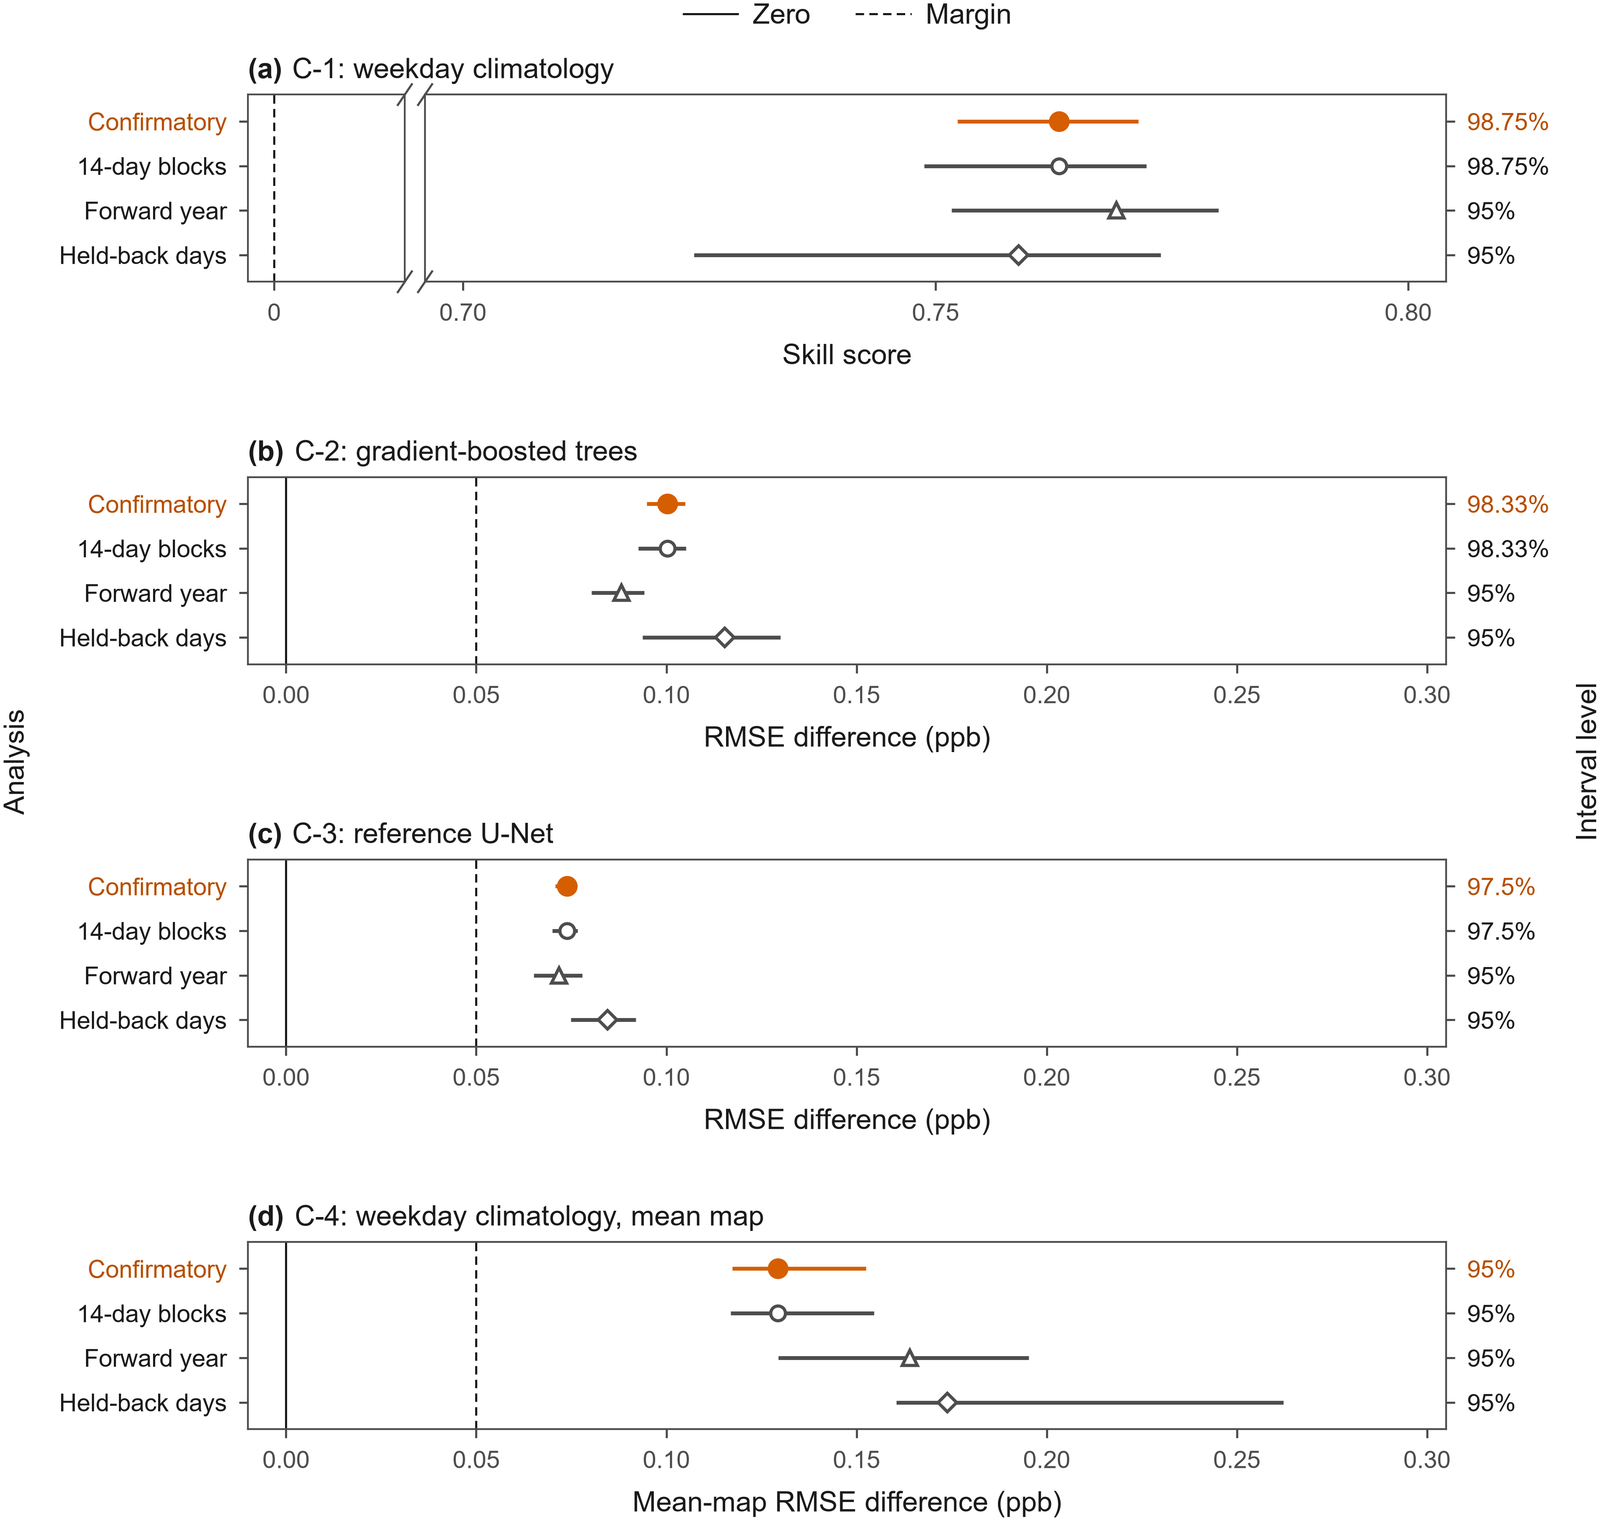

In [8]:
# @title Figure 5: Four comparisons, fixed in advance
run_builder("build_fig_F4.py")
alt = ("Four stacked panels of the four comparisons fixed in "
       "advance, each with four rows of a point and its interval.")
show_figure("fig_F4", alt)

**Figure 5.** Four comparisons, fixed in advance, of the residual U-Net with other models of daily mean surface NO<sub>2</sub>, scored against CMAQ on the contiguous US land cells of the 12 km grid, held-out years 2015 to 2019. Higher values favor the residual U-Net. Panel (a) gives C-1, its skill score (unitless) against the weekday climatology. Panels (b) to (d) give the RMSE (ppb) of the model in the title minus that of the residual U-Net: C-2 for the gradient-boosted trees, C-3 for the reference U-Net and C-4, the mean-map RMSE, for the weekday climatology. Each interval's level is printed at right. Filled vermilion circles show the mean of the five yearly values with its percentile interval at the level of its Holm step among four comparisons, from paired resamples of 7-day blocks (confirmatory). Open circles show the same with 14-day blocks (sensitivity), open triangles 2019 alone (forward year, exploratory) and open diamonds the held-back days, evaluated once (further check), the last two with unadjusted 95 percent intervals. In (b) to (d) the solid line marks zero difference; the dashed line marks the margin, 0 in (a), drawn left of the axis break, and 0.05 ppb in (b) to (d). C-4's resampled intervals lay high against their points (Section 4.4); reflected about the point, the held-back interval is 0.086 to 0.187 ppb, still above the margin. Intervals cover the sampling of test days; Figure 6 shows the spread over seeds.

All four comparisons favored the residual U-Net, and each interval, at the level of its Holm step, lay wholly beyond its margin (Figure 5; Appendix Table A4). Its skill score against the weekday climatology (C-1) was 0.763 (98.75 percent interval 0.752 to 0.771), and the median over cells of its anomaly correlation, which the test also required to be above zero, was 0.813.

<details>
<summary>Text description of Figure 5</summary>

A key line above panel (a) names a solid line Zero and a dashed line Margin. In every panel the rows, from the top, are named at the left and each row's interval level is printed at the right; one vertical title, Analysis, at the left and one, Interval level, at the right are centred on the four stacked panels. Panel (a), titled C-1: weekday climatology, shows C-1: skill score of the residual U-Net against the weekday climatology. Horizontal axis title: Skill score; ticks 0.70, 0.75, 0.80. A short broken part of the axis at its left holds the dashed margin line at 0, tick 0. Rows: Confirmatory, filled vermilion circle, 98.75%: 0.763 (0.752 to 0.771); 14-day blocks, open circle, 98.75%: 0.763 (0.749 to 0.772); Forward year, open triangle, 95%: 0.769 (0.752 to 0.780); Held-back days, open diamond, 95%: 0.759 (0.724 to 0.774). Panel (b), titled C-2: gradient-boosted trees, shows C-2: RMSE of the gradient-boosted trees minus that of the residual U-Net. Horizontal axis title: RMSE difference (ppb); ticks 0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30. A solid vertical line at 0 and a dashed vertical line at the margin, 0.05 (Margin, 0.05 ppb). Rows: Confirmatory, filled vermilion circle, 98.33%: 0.100 (0.095 to 0.105); 14-day blocks, open circle, 98.33%: 0.100 (0.093 to 0.105); Forward year, open triangle, 95%: 0.088 (0.080 to 0.094); Held-back days, open diamond, 95%: 0.115 (0.094 to 0.130). Panel (c), titled C-3: reference U-Net, shows C-3: RMSE of the reference U-Net minus that of the residual U-Net. Horizontal axis title: RMSE difference (ppb); ticks 0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30. A solid vertical line at 0 and a dashed vertical line at the margin, 0.05 (Margin, 0.05 ppb). Rows: Confirmatory, filled vermilion circle, 97.5%: 0.074 (0.071 to 0.076); 14-day blocks, open circle, 97.5%: 0.074 (0.070 to 0.077); Forward year, open triangle, 95%: 0.072 (0.065 to 0.078); Held-back days, open diamond, 95%: 0.085 (0.075 to 0.092). Panel (d), titled C-4: weekday climatology, mean map, shows C-4: mean-map RMSE of the weekday climatology minus that of the residual U-Net. Horizontal axis title: Mean-map RMSE difference (ppb); ticks 0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30. A solid vertical line at 0 and a dashed vertical line at the margin, 0.05 (Margin, 0.05 ppb). Rows: Confirmatory, filled vermilion circle, 95%: 0.129 (0.117 to 0.152); 14-day blocks, open circle, 95%: 0.129 (0.117 to 0.155); Forward year, open triangle, 95%: 0.164 (0.129 to 0.195); Held-back days, open diamond, 95%: 0.174 (0.161 to 0.262).

</details>

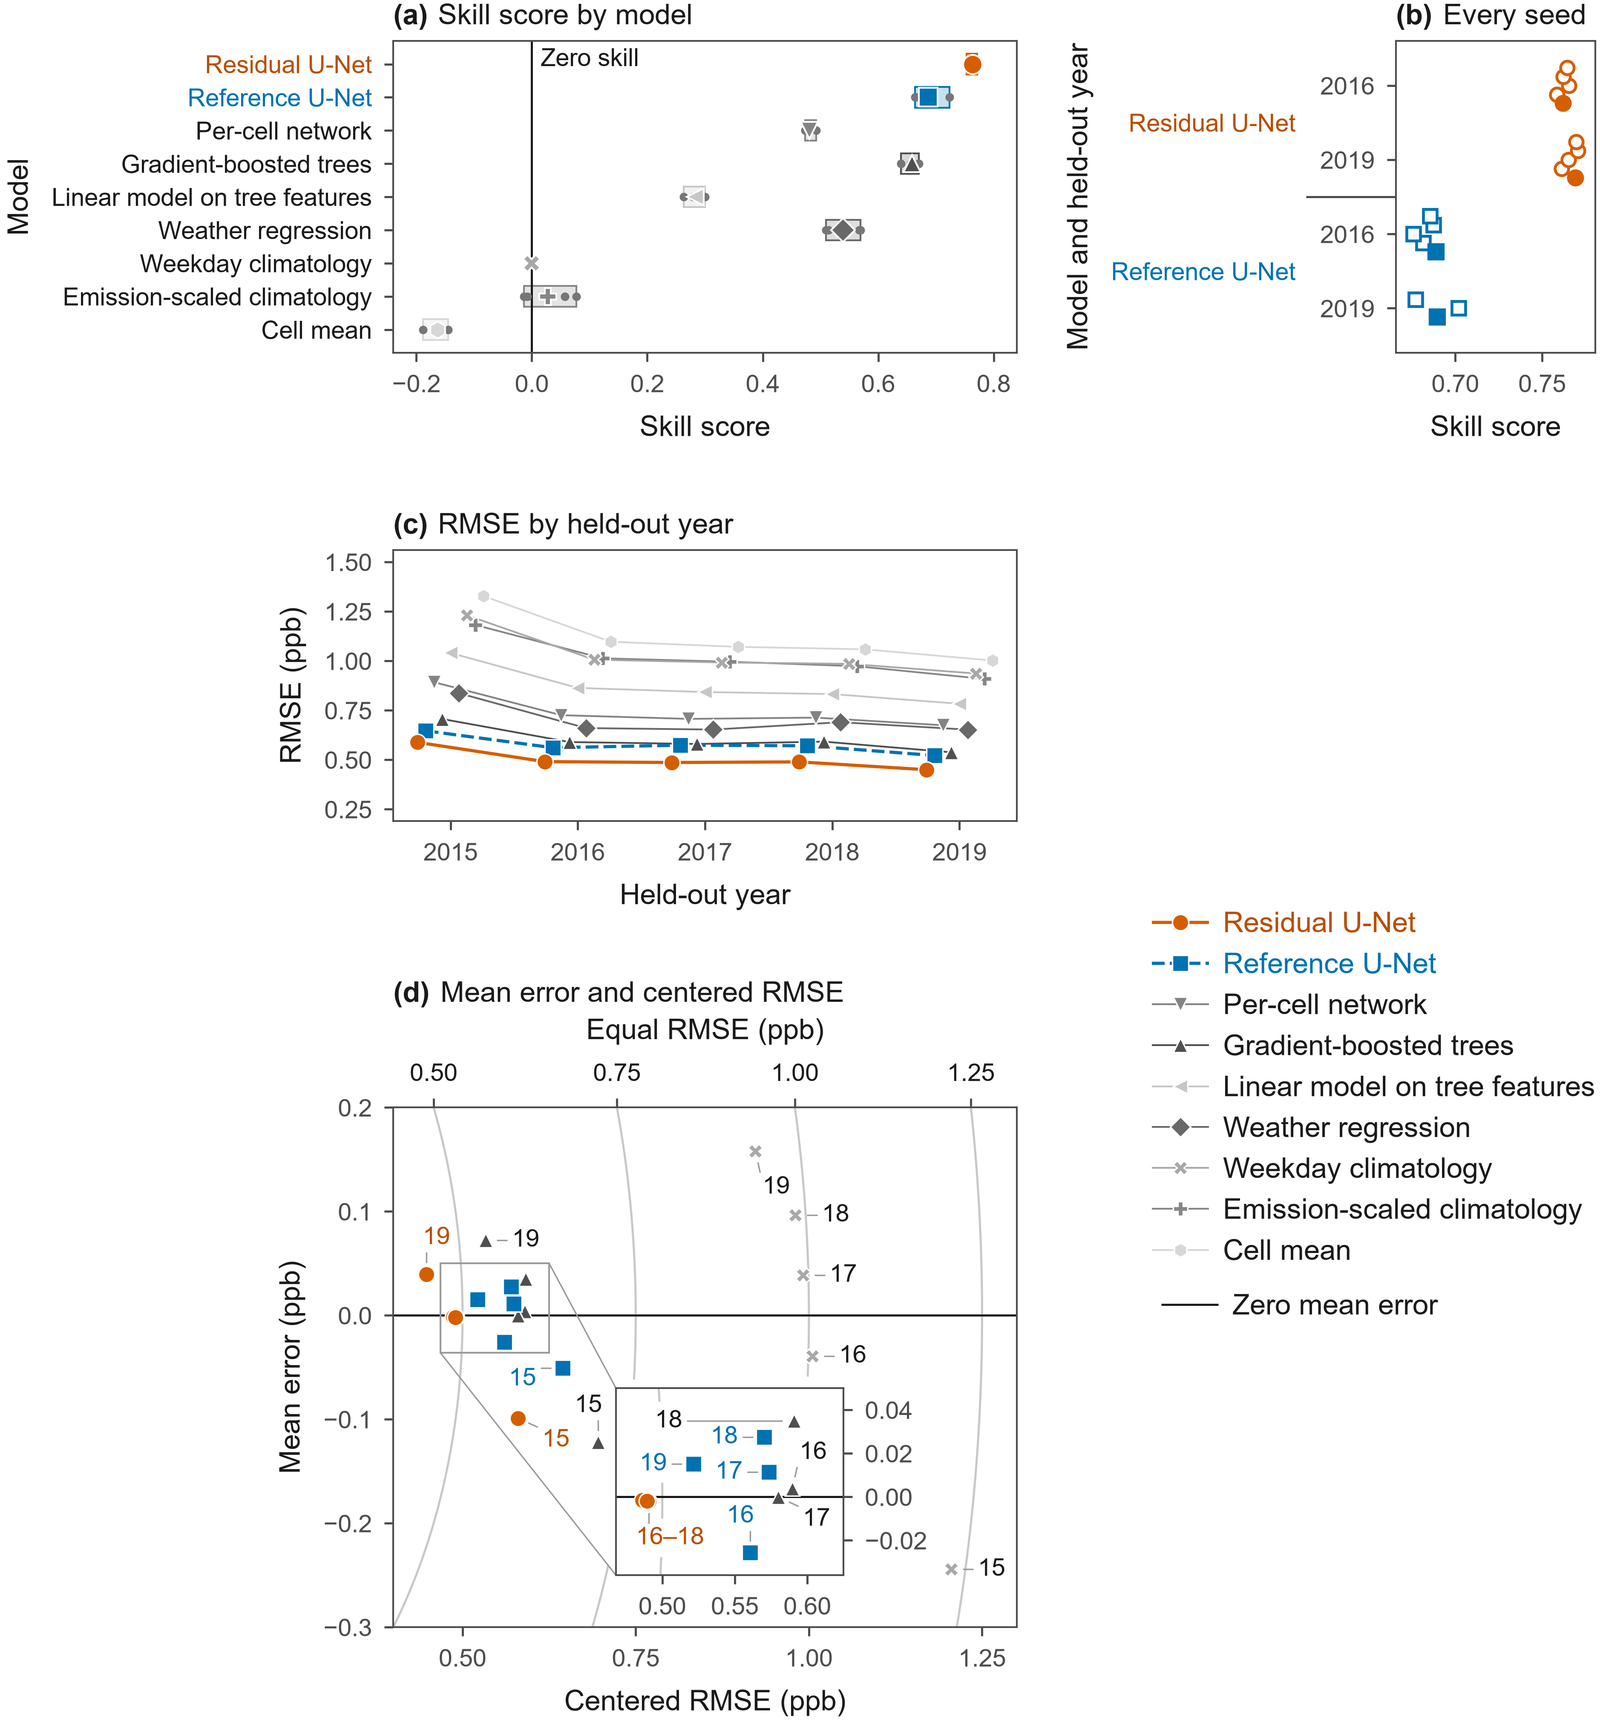

In [9]:
# @title Figure 6: Skill score, RMSE and mean error by held-out year
run_builder("build_fig_F5.py")
alt = ("Four panels: skill score by model with year ranges, U-Net "
       "seeds, RMSE by held-out year, and mean error against "
       "centered RMSE.")
show_figure("fig_F5", alt)

**Figure 6.** Skill score, RMSE and mean error of modeled daily mean NO<sub>2</sub> against CMAQ by held-out year, 2015 to 2019, test days, contiguous US land cells of the 12 km grid. Networks at seed 0; baselines one fit per fold. (a) Skill score against the weekday climatology; the large mark is the five-year mean, small gray dots the single years and the pale band their range (lowest to highest). (b) Every seed, 2016 and 2019 (residual U-Net, five seeds in each year; reference U-Net, five seeds in 2016 and three in 2019), with seed 0 filled. (c) RMSE (ppb), offset within years. (d) Mean error against centered RMSE (Equation (3); ppb) of the two U-Nets, the gradient-boosted trees and the weekday climatology, with marks labeled by year (two digits, each joined to its mark by a gray line; coinciding marks share one label). Gray rings join points of equal RMSE, with their values (ppb) on the scale over the panel, and mean error is drawn at 1.5 times the scale of centered RMSE. The inset magnifies the boxed area. The mean error is a domain mean; urban and rural errors can cancel. Panels (b) and (d) were not specified in advance.

The emulators' errors were lower than those of the simplest baselines, and the gradient-boosted trees came closer to the emulators (Figure 6). As means of the five yearly values (Appendix Table A5; every training in Appendix Table A6), the RMSE was 1.030 ppb for the weekday climatology, 0.601 ppb for the gradient-boosted trees, 0.575 ppb for the reference U-Net and 0.501 ppb for the residual U-Net.

<details>
<summary>Text description of Figure 6</summary>

Panel (a) Skill score by model: one row per model, from the top Residual U-Net; Reference U-Net; Per-cell network; Gradient-boosted trees; Linear model on tree features; Weather regression; Weekday climatology; Emission-scaled climatology; Cell mean; vertical axis Model; horizontal axis Skill score; each row a large mark at the five-year mean, small filled gray dots for each year and a pale band over their range; a vertical line at 0, labeled Zero skill at its upper end. Panel (b) Every seed: vertical axis Model and held-out year, rows 2016 and 2019 under Residual U-Net, then 2016 and 2019 under Reference U-Net; horizontal axis Skill score; open marks for each seed, filled for seed 0. Panel (c) RMSE by held-out year: vertical axis RMSE (ppb); horizontal axis Held-out year, 2015 to 2019; each model a line of marks, set apart within each year. The key at the right of (c) and (d) names the nine models in the order of (a); under it a solid black line is keyed Zero mean error. Panel (d) Mean error and centered RMSE: horizontal axis Centered RMSE (ppb), vertical axis Mean error (ppb); gray rings of equal RMSE, with values 0.50, 0.75, 1.00 and 1.25 on a scale over the frame titled Equal RMSE (ppb), each value over a tick where its ring meets the top of the frame; a line at 0, keyed Zero mean error under the models' key; marks of Residual U-Net, Reference U-Net, Gradient-boosted trees, Weekday climatology, each labeled by its year's last two digits and joined to it by a short gray line; a gray box around the crowded marks of the U-Nets and the trees near zero mean error, drawn magnified in an inset in the lower middle, joined to the box by two gray lines; the marks in the box are labeled in the inset; mean error is drawn at 1.5 times the scale of centered RMSE, here and in the inset, so the rings appear as stretched arcs.

</details>

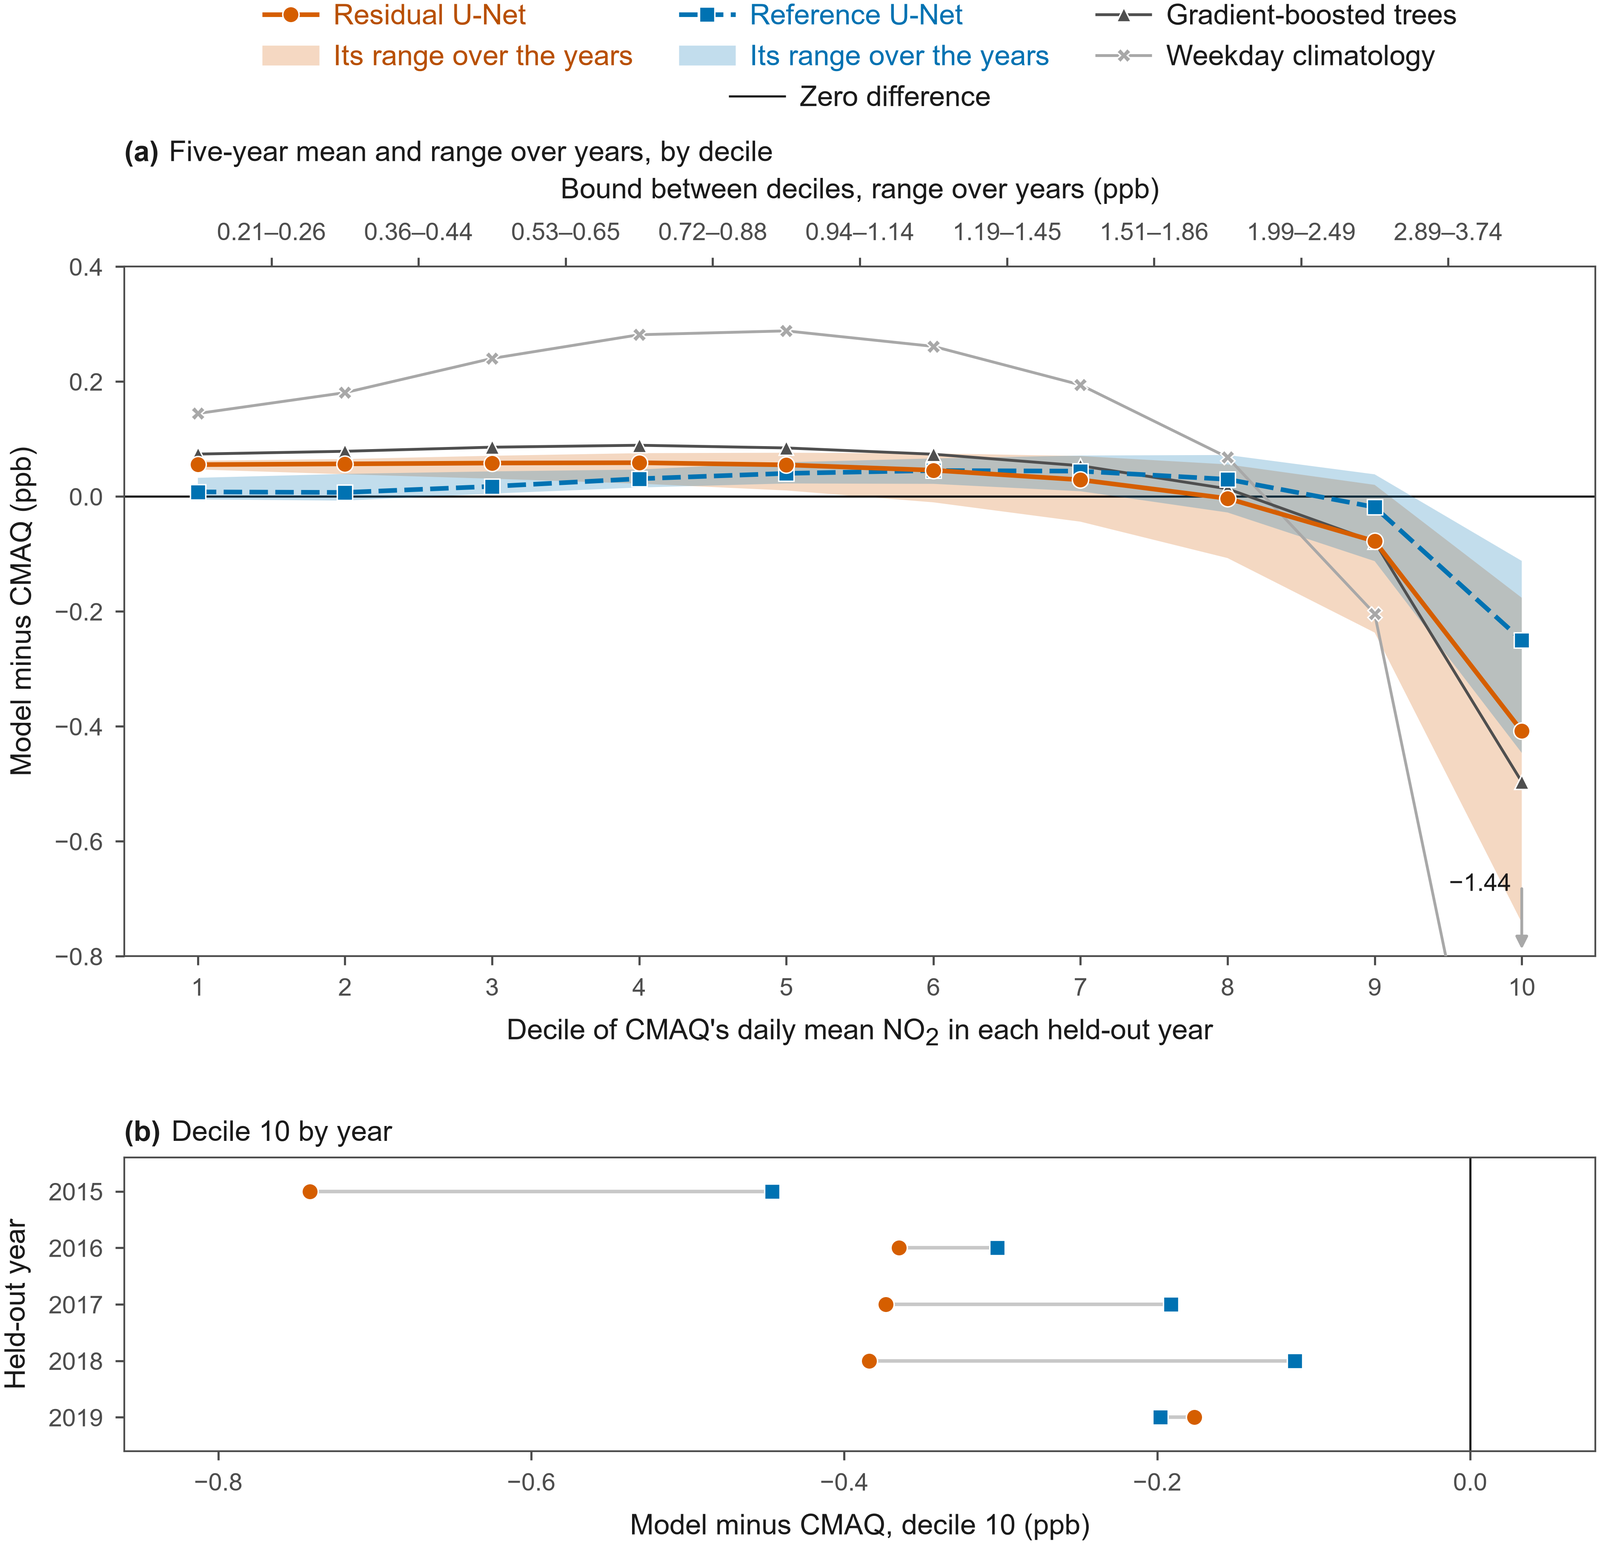

In [10]:
# @title Figure 7: Mean error in each decile of CMAQ's cell-days
run_builder("build_fig_F6.py")
alt = ("Mean error by CMAQ decile for two U-Nets with year ranges, "
       "two baselines, and decile 10 by year.")
show_figure("fig_F6", alt)

**Figure 7.** Mean error of modeled daily mean NO<sub>2</sub> (ppb, the model minus CMAQ) in each decile of CMAQ's cell-days, contiguous US land cells of the 12 km grid, test days of the held-out years 2015 to 2019. Deciles are set within each held-out year (10 the highest); the top axis of (a) gives each bound's range over the years. (a) Lines show the unweighted five-year mean (U-Nets at seed 0), and the light vermilion and light blue bands the residual and the reference U-Net's range over the years (lowest to highest), gray where they overlap. The weekday climatology's decile-10 mean, below the axis, is marked by an arrow with its value. (b) Decile 10 in each held-out year; a gray line joins one year's two U-Net values. The black line marks zero difference. Grouping by CMAQ's own value lets regression toward the mean make a smoother model read low where CMAQ is high. Panel (b) was not specified in advance.

On CMAQ's highest cell-days both emulators were below CMAQ on average (Figure 7); because the cell-days are grouped by CMAQ's own decile, a model smoother than CMAQ tends to fall below it in the top decile. For the residual U-Net the top-decile mean error ranged from &minus;0.74 to &minus;0.18 ppb by year, and for the reference U-Net from &minus;0.45 to &minus;0.11 ppb.

<details>
<summary>Text description of Figure 7</summary>

Key above, three columns, the last entry, a black line, centred in a row of its own: Residual U-Net; Its range over the years; Reference U-Net; Its range over the years; Gradient-boosted trees; Weekday climatology; Zero difference. Panel (a) Five-year mean and range over years, by decile: horizontal axis Decile of CMAQ's daily mean NO2 in each held-out year, ticks 1 to 10; top axis Bound between deciles, range over years (ppb), between deciles 1 to 2: 0.21 to 0.26; 2 to 3: 0.36 to 0.44; 3 to 4: 0.53 to 0.65; 4 to 5: 0.72 to 0.88; 5 to 6: 0.94 to 1.14; 6 to 7: 1.19 to 1.45; 7 to 8: 1.51 to 1.86; 8 to 9: 1.99 to 2.49; 9 to 10: 2.89 to 3.74; vertical axis Model minus CMAQ (ppb); a line at 0. The light vermilion band and the light blue band both widen toward decile 10, where all four mean lines fall below 0; the weekday climatology's line leaves the panel at its lower edge, marked by a downward arrow and the value minus 1.44. Panel (b) Decile 10 by year, below panel (a) at the same width: rows 2015 to 2019 (vertical axis Held-out year); horizontal axis Model minus CMAQ, decile 10 (ppb); a disc for the residual U-Net and a square for the reference U-Net in each year, joined by a gray line; a line at 0.

</details>

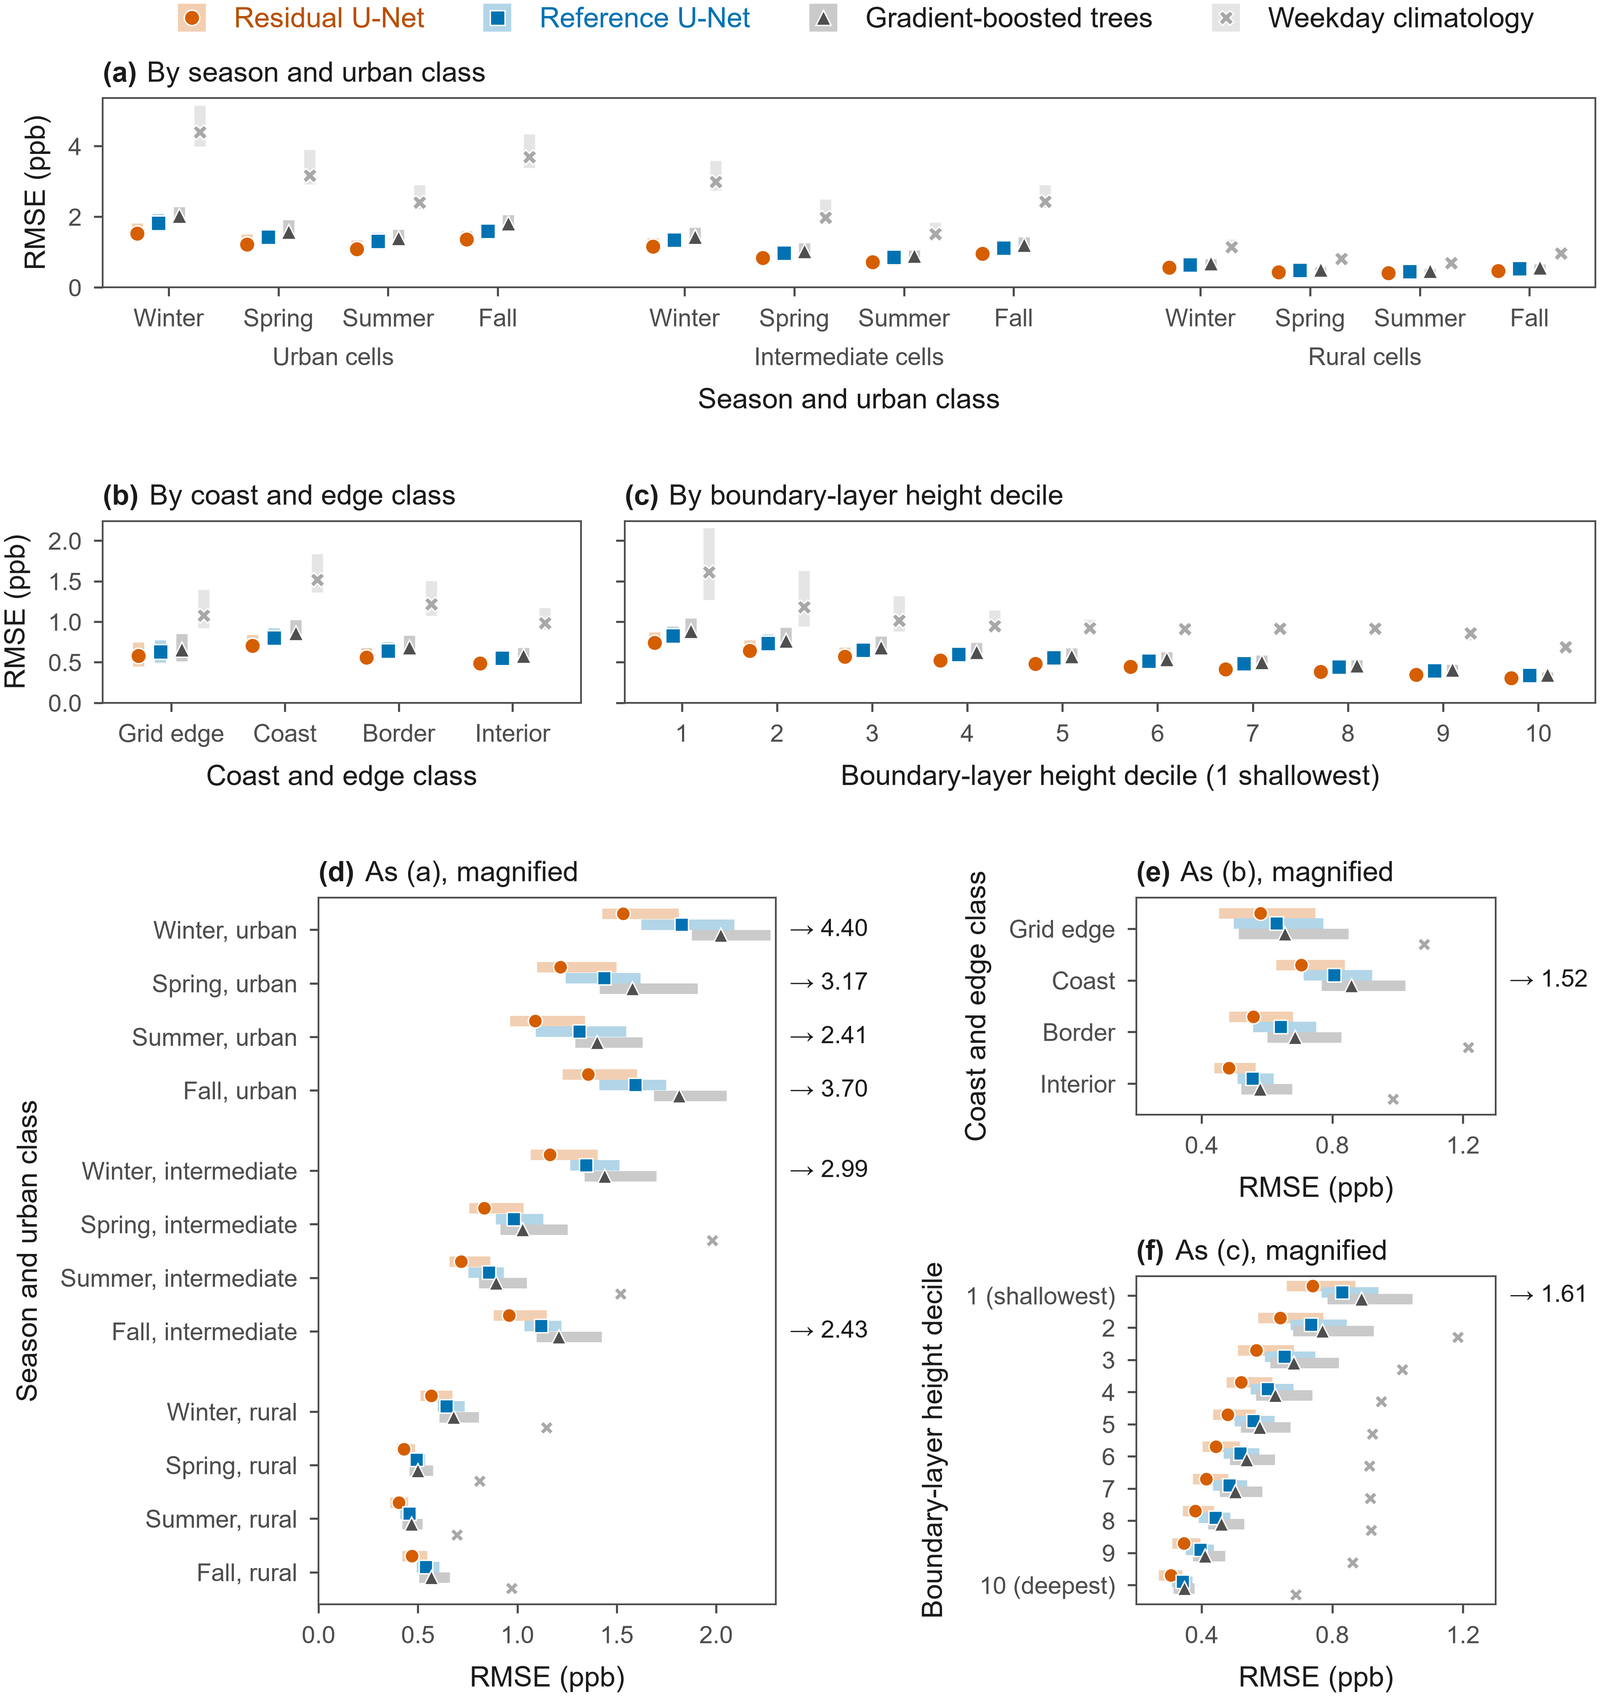

In [11]:
# @title Figure 8: RMSE by season, place and boundary-layer height
run_builder("build_fig_A_F6.py")
alt = ("Dot charts of RMSE for four models by season and urban "
       "class, coast class and boundary-layer decile, then "
       "magnified.")
show_figure("fig_A_F6", alt)

**Figure 8.** Error of modeled daily mean surface NO<sub>2</sub> against CMAQ by stratum: RMSE (ppb) on the contiguous US land cells of the 12 km grid, held-out years 2015 to 2019. Each mark is the mean of the five yearly RMSEs and its pale bar their range (lowest to highest). U-Nets at seed 0. (a) By season and urban class (urban fraction of the cell: urban at least 0.5, intermediate 0.1 to under 0.5, rural under 0.1; winter (JFD) is January, February and December of each held-out year, the December of 2019 held back or kept as buffer days, spring (MAM) March to May, summer (JJA) June to August and fall (SON) September to November). (b) By coast and edge class (grid edge, coast, border and interior; cells per class: grid edge 710, coast 1,855, border 4,151, interior 46,878). (c) By decile of daily mean boundary-layer height, set within each held-out year. (d) to (f) repeat (a) to (c) on narrower axes for the U-Nets and trees; there the climatology shows its mean alone, and arrows at right give values beyond the axis. The strata are unequal in size and not independent. Panels (d) to (f) were not specified in advance.

The errors also differed by season and by place (Figure 8; Appendix Table A8), with cells grouped by their urban fraction as urban (at least 0.5), intermediate (0.1 to under 0.5) and rural (under 0.1). For the residual U-Net the RMSE was largest in winter (0.605 ppb) and smallest in summer (0.426 ppb), as means of the five yearly values, and it was larger in urban cells (1.304 ppb) than in rural ones (0.470 ppb).

<details>
<summary>Text description of Figure 8</summary>

Key in one row: Residual U-Net; Reference U-Net; Gradient-boosted trees; Weekday climatology; each a mark on a pale bar. Panel (a) By season and urban class: vertical axis RMSE (ppb), ticks 0, 2, 4; horizontal axis Season and urban class: Winter, Spring, Summer, Fall under each of Urban cells, Intermediate cells, Rural cells. Means: Urban cells winter: Residual U-Net 1.53, Reference U-Net 1.83, Gradient-boosted trees 2.02, Weekday climatology 4.40; Urban cells spring: Residual U-Net 1.22, Reference U-Net 1.44, Gradient-boosted trees 1.58, Weekday climatology 3.17; Urban cells summer: Residual U-Net 1.09, Reference U-Net 1.31, Gradient-boosted trees 1.40, Weekday climatology 2.41; Urban cells fall: Residual U-Net 1.36, Reference U-Net 1.59, Gradient-boosted trees 1.81, Weekday climatology 3.70; Intermediate cells winter: Residual U-Net 1.16, Reference U-Net 1.35, Gradient-boosted trees 1.44, Weekday climatology 2.99; Intermediate cells spring: Residual U-Net 0.83, Reference U-Net 0.98, Gradient-boosted trees 1.03, Weekday climatology 1.98; Intermediate cells summer: Residual U-Net 0.72, Reference U-Net 0.86, Gradient-boosted trees 0.89, Weekday climatology 1.52; Intermediate cells fall: Residual U-Net 0.96, Reference U-Net 1.12, Gradient-boosted trees 1.21, Weekday climatology 2.43; Rural cells winter: Residual U-Net 0.57, Reference U-Net 0.64, Gradient-boosted trees 0.68, Weekday climatology 1.15; Rural cells spring: Residual U-Net 0.43, Reference U-Net 0.49, Gradient-boosted trees 0.50, Weekday climatology 0.81; Rural cells summer: Residual U-Net 0.40, Reference U-Net 0.46, Gradient-boosted trees 0.47, Weekday climatology 0.70; Rural cells fall: Residual U-Net 0.47, Reference U-Net 0.54, Gradient-boosted trees 0.57, Weekday climatology 0.97. Panel (b) By coast and edge class: vertical axis RMSE (ppb), ticks 0.0, 0.5, 1.0, 1.5, 2.0; horizontal axis Coast and edge class: Grid edge (710 cells), Coast (1,855 cells), Border (4,151 cells), Interior (46,878 cells). Means: Grid edge: Residual U-Net 0.58, Reference U-Net 0.63, Gradient-boosted trees 0.66, Weekday climatology 1.08; Coast: Residual U-Net 0.71, Reference U-Net 0.81, Gradient-boosted trees 0.86, Weekday climatology 1.52; Border: Residual U-Net 0.56, Reference U-Net 0.64, Gradient-boosted trees 0.69, Weekday climatology 1.22; Interior: Residual U-Net 0.48, Reference U-Net 0.56, Gradient-boosted trees 0.58, Weekday climatology 0.99. Panel (c) By boundary-layer height decile: on the vertical scale of panel (b), ticked, not labeled again; horizontal axis Boundary-layer height decile (1 shallowest), deciles 1, 2, 3, 4, 5, 6, 7, 8, 9, 10. Means: decile 1: Residual U-Net 0.74, Reference U-Net 0.83, Gradient-boosted trees 0.89, Weekday climatology 1.61; decile 2: Residual U-Net 0.64, Reference U-Net 0.74, Gradient-boosted trees 0.77, Weekday climatology 1.18; decile 3: Residual U-Net 0.57, Reference U-Net 0.65, Gradient-boosted trees 0.68, Weekday climatology 1.01; decile 4: Residual U-Net 0.52, Reference U-Net 0.60, Gradient-boosted trees 0.62, Weekday climatology 0.95; decile 5: Residual U-Net 0.48, Reference U-Net 0.56, Gradient-boosted trees 0.58, Weekday climatology 0.92; decile 6: Residual U-Net 0.44, Reference U-Net 0.52, Gradient-boosted trees 0.54, Weekday climatology 0.91; decile 7: Residual U-Net 0.41, Reference U-Net 0.49, Gradient-boosted trees 0.50, Weekday climatology 0.92; decile 8: Residual U-Net 0.38, Reference U-Net 0.44, Gradient-boosted trees 0.46, Weekday climatology 0.92; decile 9: Residual U-Net 0.35, Reference U-Net 0.40, Gradient-boosted trees 0.41, Weekday climatology 0.86; decile 10: Residual U-Net 0.31, Reference U-Net 0.34, Gradient-boosted trees 0.35, Weekday climatology 0.69. Panel (d) As (a), magnified: vertical axis Season and urban class, rows Winter, urban, Spring, urban, Summer, urban, Fall, urban, Winter, intermediate, Spring, intermediate, Summer, intermediate, Fall, intermediate, Winter, rural, Spring, rural, Summer, rural, Fall, rural; horizontal axis RMSE (ppb), ticks 0.0, 0.5, 1.0, 1.5, 2.0; weekday climatology means beyond the axis printed after an arrow: winter, urban 4.40; spring, urban 3.17; summer, urban 2.41; fall, urban 3.70; winter, intermediate 2.99; fall, intermediate 2.43. Panel (e) As (b), magnified: vertical axis Coast and edge class, rows Grid edge, Coast, Border, Interior. Panel (f) As (c), magnified: vertical axis Boundary-layer height decile, rows 1 (shallowest), 2, 3, 4, 5, 6, 7, 8, 9, 10 (deepest). Each on the same horizontal axis RMSE (ppb), ticks 0.4, 0.8, 1.2; weekday climatology means beyond it printed after an arrow: coast 1.52; boundary-layer decile 1 1.61.

</details>

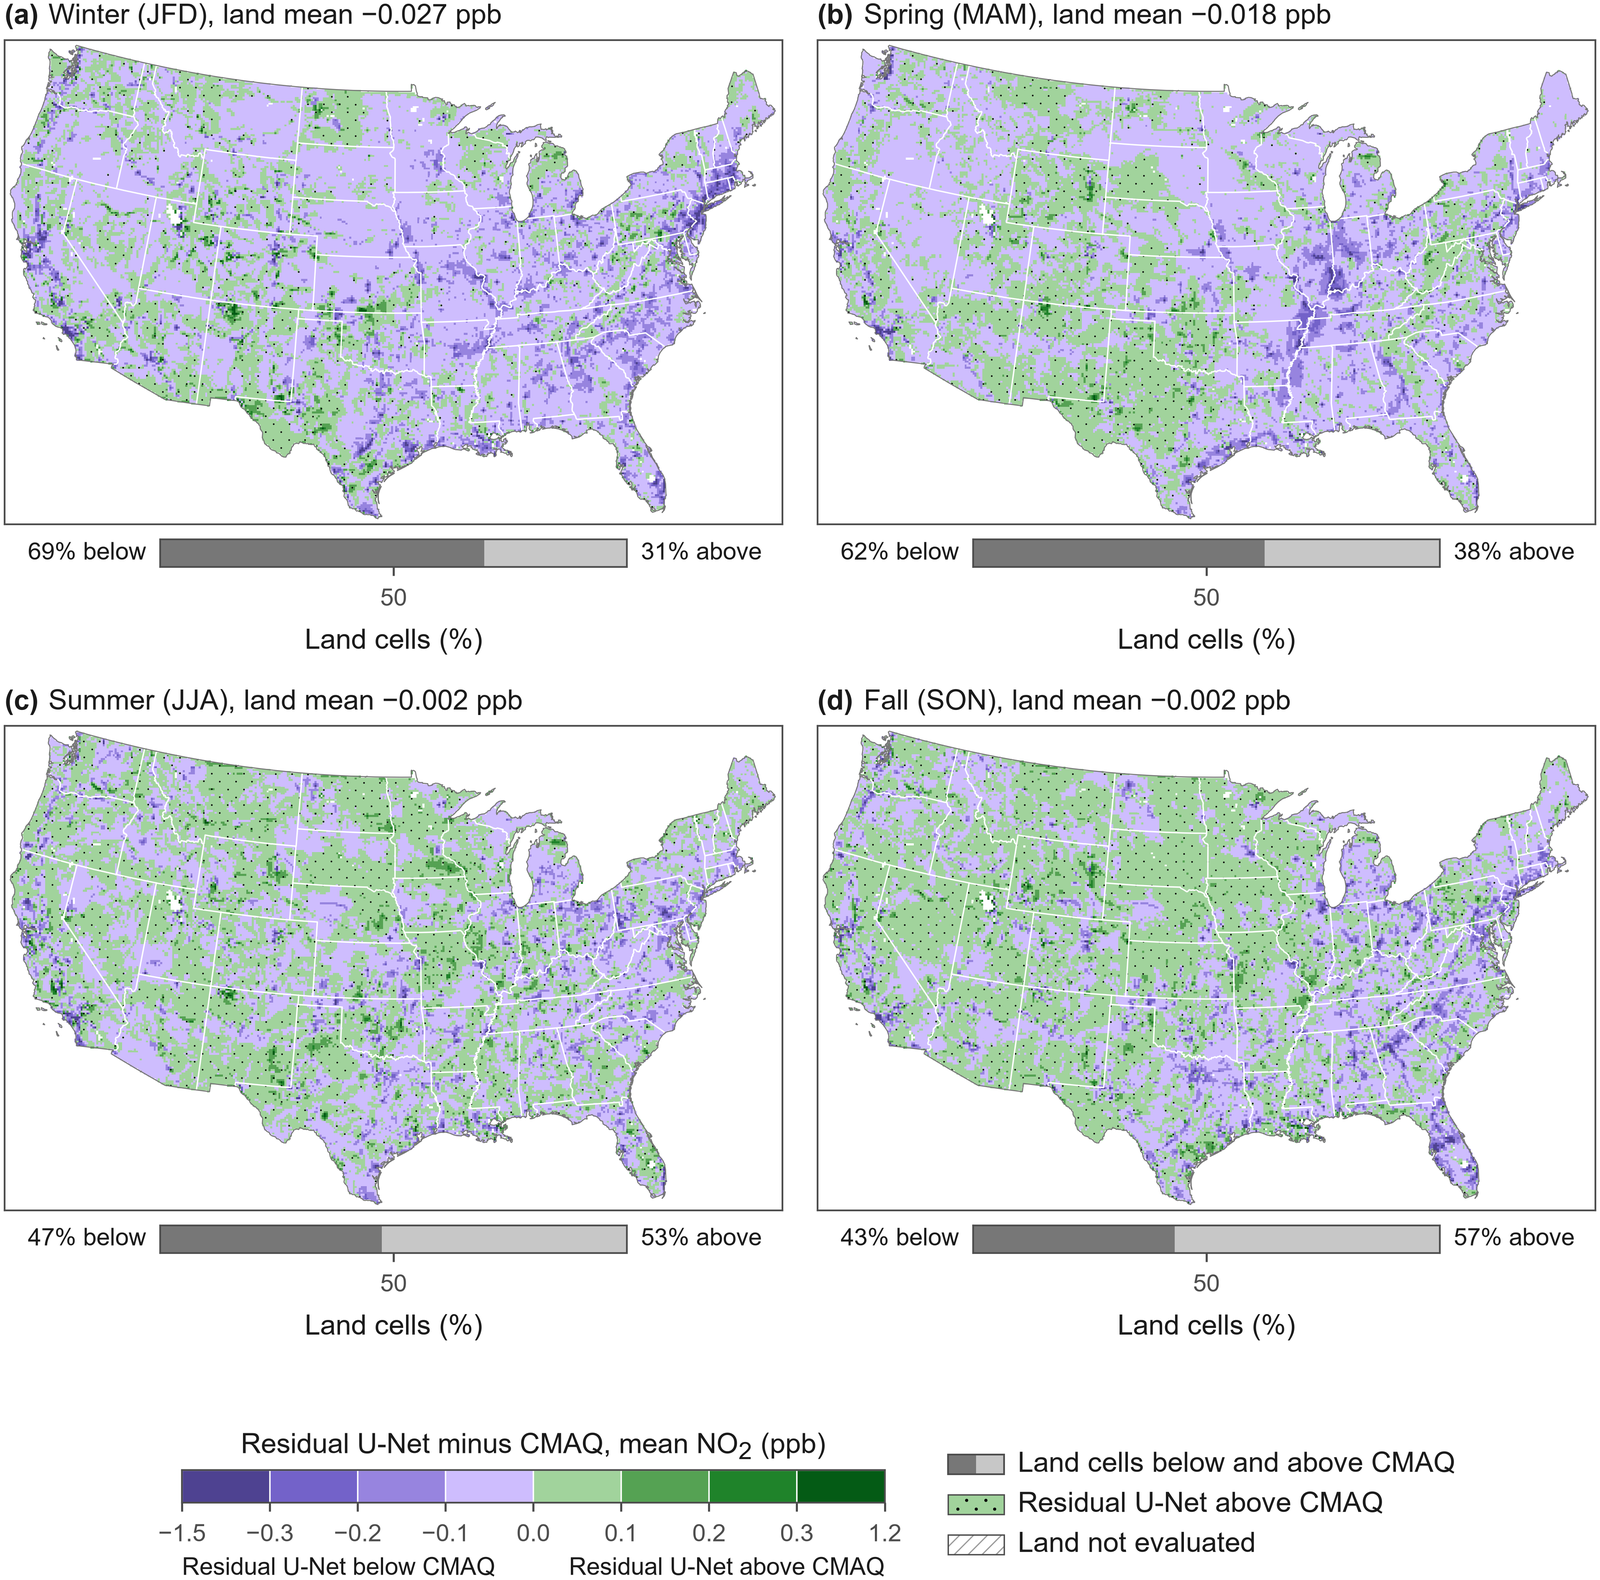

In [12]:
# @title Figure 9: Residual U-Net minus CMAQ, mean by season
# drawn by build_fig_maps.py with Figure 2
alt = ("Four US maps by season: the residual U-Net minus CMAQ, mean "
       "of five held-out years, purple below and green above.")
show_figure("fig_F7", alt, folder=MAPS)

**Figure 9.** Mean difference between the residual U-Net and CMAQ in modeled daily mean surface NO<sub>2</sub> (ppb) by season, contiguous US land cells of the 12 km grid, test days of the held-out years 2015 to 2019. (a) Winter (JFD, each year's January, February and December, without December 2019), (b) spring (MAM), (c) summer (JJA) and (d) fall (SON). Each map averages the five yearly seasonal means. Steps of 0.1 ppb, purple below CMAQ and green above; outer classes run beyond &plusmn;0.3 ppb. Each bar gives the shares of land cells below CMAQ (dark gray) and above (light gray). In each season 87 to 91 percent of the cells lay within 0.1 ppb of CMAQ (Section 4.7). Dots mark the cells above CMAQ, the rarer sign over the figure's difference maps. Hatching marks the 85 cells of US land not evaluated, and white marks water and land outside the US; white lines are state boundaries and the gray line the coast and national borders. The maps use an equal-area projection.

The residual U-Net's mean error was small in every season, and the sign held by most cells changed with the season (Figure 9), while the mean over the land cells was below zero in every season, from &minus;0.027 ppb in winter to &minus;0.002 ppb in summer and fall (Appendix Table A8). The residual U-Net was below CMAQ in most cells in winter and spring (69 and 62 percent of the cells) and above it in most cells in summer and fall (below in 47 and 43 percent). As with the signs of the 2016 mean map (Section 4.2), these shares are those of one training in each year.

<details>
<summary>Text description of Figure 9</summary>

Four maps of the contiguous United States in an equal-area projection, two by two: (a) winter (JFD), (b) spring (MAM), (c) summer (JJA), (d) fall (SON), each titled with its land mean (-0.027, -0.018, -0.002 and -0.002 ppb). Each cell shows the residual U-Net minus CMAQ, the mean of the five held-out years, in four purple classes (below CMAQ) and four green classes (above CMAQ), steps of 0.1 ppb; dots mark the cells where the emulator is above CMAQ. Under each map a bar splits its land cells into those below CMAQ (dark gray, share printed at the left) and above it (light gray, share at the right), with a mark at 50 percent (69 and 31, 62 and 38, 47 and 53, 43 and 57 percent). One key block under the maps: at the left a color bar titled Residual U-Net minus CMAQ, mean NO2 (ppb), with the lowest and highest values, -1.5 and 1.2 ppb, at its ends and the two sides named under them; at the right three entries name the bars, the dots and the hatch. Hatching marks the 85 cells of US land not evaluated; white lines are state boundaries and a gray line the coast and national borders; water and land outside the US are white.

</details>

<a id="5-limitations" name="5-limitations"></a>

## 5. Limitations

Every error in this report is measured against CMAQ's output, so how close the emulators are to observed NO<sub>2</sub> depends also on CMAQ's own error, which was not assessed. The residual U-Net takes each date's emissions as inputs, but whether it responds as CMAQ does when emissions change was not tested, so its use for emission scenarios awaits that test. In 2015, 2018 and 2019, between 21 and 31 percent of the test cell-days had an emission input outside the range the cell saw in training. The residual U-Net also reads CMAQ's weekday climatology of the training years, so a use for emission scenarios would also have to settle whether that climatology is kept as fitted or rebuilt under the changed emissions, and to test the result against CMAQ runs with perturbed emissions. Biogenic, lightning, fire and residential wood combustion emissions were not inputs, so the emulators can follow their effect on CMAQ's NO<sub>2</sub> only through the other inputs; stack emissions were inputs but entered at the surface, without the rise of their plumes. Like the published emulator (Payami et al., 2025, p. 13), the two emulators do not replicate CMAQ's processes: they hold no chemical state, boundary conditions or vertical structure, and each day is predicted on its own from that day's inputs; only the residual U-Net reads anything of an earlier day, five weather fields of the day before. Nor do they read the ozone and photolysis rates that CMAQ computes, which set the split between NO and NO<sub>2</sub>; solar radiation at the ground is their only proxy among the inputs, and the winds above the lowest model layer are not read. On the cell-days above 30 ppb the residual U-Net's correlation with CMAQ was low and varied widely from year to year (&minus;0.33 to 0.58), and those cell-days are few (156 to 656 a year). A correlation among cell-days selected by CMAQ's own high value tends to be low for any model, because the selection narrows CMAQ's range. Over the five years the residual U-Net was on average slightly below CMAQ in urban cells (mean error &minus;0.142 ppb, against &minus;0.010 ppb in rural cells; Appendix Table A8), though not in 2019 (0.207 ppb). The results hold for 2015 to 2019, daily means of the UTC day and the land cells of the contiguous United States in EQUATES. The effect of the stand-in inputs, and of a climatology fitted on three training years for training days but on four for test days, was not measured.

The intervals cover the sampling of test days for the trained models; training randomness and errors in the inputs are outside them. So is the variation from one year to another, since the intervals hold the five years fixed, and the models of any two folds share three of their four training years. The results may hold only for places the networks were trained on. In an exploratory test with 2016 held out, an intermediate network (step 3 of Appendix G) trained with one block of cells left out of its loss, but with that block's CMAQ climatology among its inputs, had a larger RMSE on that block, by 0.101 ppb (95 percent interval 0.088 to 0.115), than the same network trained with that block in its loss (Appendix Figure A8). This is a probe, not a spatial hold-out. Training randomness was measured in the 2016 and 2019 folds only; the other years carry one training of each network. The seed ranges come from 3 to 5 trainings, so they tend to understate the spread that more trainings would show. Of the 18 trainings at 16,000 steps, 8 had their best validation score at their last step (4 of the 13 residual U-Net trainings), as had 16 of the 33 at 6,000 (8 of the 11 reference U-Net trainings), so longer training might have lowered their error further. The gradient-boosted trees also had their lowest validation error at their last iteration in every held-out year, so C-2 compares the residual U-Net with trees that more iterations might have improved.

Four analysis choices that the analysis plan does not state were set in the evaluation code, which was fixed before the evaluation ran. They are the form of Holm's procedure (applied to p-values from the resamples), the handling of blocks across the held-back days, the seed rule's form as the range of each model's values across its repeated trainings and the margin of 0.05 ppb for the exploratory comparisons. The results reported here use them.

<a id="6-rerun" name="6-rerun"></a>

## 6. How to rerun each stage

The pipeline ran in the order of the numbered folders of `pipeline/`; `pipeline/README.md` gives what each stage read and wrote, what it ran on and its recorded run time, and `environment/requirements-pipeline.txt` the package versions pinned for the pipeline. The networks were trained on Colab runtimes with NVIDIA A100 GPUs, and the data steps, the baselines and the evaluation ran on Colab's high-memory CPU runtimes. Each stage is rerun by its driver, run as a script with the runtime's Python. The drivers of stages 1 to 5 run their whole stage in one call, for example `python -I -B -u rsig_colab_driver.py`; those of stages 6 to 8 take one step name as their one argument and are called once for each step, in the order of the table, for example `python -I -B -u eval_colab_driver.py gates`.

| Folder | Driver | Steps, in order |
|---|---|---|
| `1_rsig_download` | `rsig_colab_driver.py` | the whole stage |
| `2_aws_extraction` | `c5_colab_driver.py` | the whole stage |
| `3_drive_extraction` | `c7a_colab_driver.py` | the whole stage |
| `4_arrays` | `p2_colab_driver.py` | the whole stage |
| `5_fills_and_statistics` | `s8_colab_driver.py` | the whole stage |
| `6_cpu_baselines` | `cpu_colab_driver.py` | `session`, `gates`, `copy`, `pd17`, `norm_f6`, `ctables`, `baselines`, `end` |
| `6_cpu_norm_2019` | `cpu_t2_driver.py` | `session`, `gates`, `copy`, `norm`, `end` |
| `7_train_reference` | `train_colab_driver.py` | `session`, `gates`, `copy`, `equiv`, `timing`, `env`, `train`, `end` |
| `7_train_residual` | `train2_colab_driver.py` | `session`, `gates`, `copy`, `equiv`, `timing`, `train`, `lockbox_pred`, `end` |
| `8_evaluation` | `eval_colab_driver.py` | `session`, `gates`, `copy`, `cv`, `lockbox`, `end` |

The steps of stages 6 to 8 do the following.

| Step | What it does |
|---|---|
| `session` | Records the Colab session (its start, its hours and its processor) and does nothing else |
| `gates` | Checks the markers of the earlier stages, the configuration and the runtime before any work |
| `copy` | Copies the configuration files and the input arrays to the runtime, with size checks |
| `pd17` | Makes a read-only pass over every input array (its sha256 and its non-finite, fill and negative values) before any fit |
| `norm_f6` | Rewrites the scaling statistics of the climatological-emission folds of 2016 and 2018 and of the two-year emission tests with the held-back and buffer days left out |
| `ctables` | Builds the climatology tables of each fold |
| `baselines` | Refits the baselines on each fold's training days and writes their predictions |
| `norm` | Rewrites the scaling statistics of the climatological-emission fold with 2019 held out in the same way |
| `equiv` | Runs the equivalence test of the training code on the runtime's device |
| `timing` | Times the networks' training steps on the runtime's GPU, for the choice of GPU type |
| `env` | Checks that the runtime's GPU is of the type the timing step chose |
| `train` | Runs the trainings, each resumable from its checkpoints, and predicts the held-out year |
| `lockbox_pred` | Writes the held-back-day predictions of every finished training |
| `cv` | Evaluates the models on the test days of the five held-out years |
| `lockbox` | Evaluates the models on the held-back days, once their gate is open |
| `end` | Records the compute used and what is done and what is left |

The figures of the report, and its tables except Tables 1 and A1, which are text of the report, are rebuilt from `results/` by the scripts in `report/`, each run from the repository root (for example `python report/build_fig_F1.py`); this notebook runs those of the main figures.

<a id="7-references" name="7-references"></a>

## 7. References

* Foley, K. M., Pouliot, G. A., Eyth, A., Aldridge, M. F., Allen, C., Appel, K. W., Bash, J. O., Beardsley, M., Beidler, J., Choi, D., Farkas, C., Gilliam, R. C., Godfrey, J., Henderson, B. H., Hogrefe, C., Koplitz, S. N., Mason, R., Mathur, R., Misenis, C., Possiel, N., Pye, H. O. T., Reynolds, L., Roark, M., Roberts, S., Schwede, D. B., Seltzer, K. M., Sonntag, D., Talgo, K., Toro, C., Vukovich, J., Xing, J., Adams, E. (2023). 2002&ndash;2017 anthropogenic emissions data for air quality modeling over the United States. *Data in Brief* 47, 109022. <https://doi.org/10.1016/j.dib.2023.109022>
* Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del R&iacute;o, J. F., Wiebe, M., Peterson, P., G&eacute;rard-Marchant, P., Sheppard, K., Reddy, T., Weckesser, W., Abbasi, H., Gohlke, C., Oliphant, T. E. (2020). Array programming with NumPy. *Nature* 585, 357&ndash;362. <https://doi.org/10.1038/s41586-020-2649-2>
* He, K., Zhang, X., Ren, S., Sun, J. (2016). Deep residual learning for image recognition. In 2016 IEEE Conference on Computer Vision and Pattern Recognition (CVPR) (pp. 770&ndash;778). IEEE. <https://doi.org/10.1109/CVPR.2016.90>
* Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics* 6, 65&ndash;70. <https://www.jstor.org/stable/4615733>
* Hu, J., Shen, L., Sun, G. (2018). Squeeze-and-excitation networks. In 2018 IEEE/CVF Conference on Computer Vision and Pattern Recognition (pp. 7132&ndash;7141). IEEE. <https://doi.org/10.1109/CVPR.2018.00745>
* Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science &amp; Engineering* 9, 90&ndash;95. <https://doi.org/10.1109/MCSE.2007.55>
* Manson, S., Schroeder, J., Van Riper, D., Knowles, K., Kugler, T., Roberts, F., Ruggles, S. (2024). IPUMS National Historical Geographic Information System: Version 19.0. Dataset. Minneapolis, MN: IPUMS. <https://doi.org/10.18128/D050.V19.0>
* Natural Earth (2022). 1:10m Cultural Vectors: Admin 1 &ndash; States, Provinces (large lakes removed), version 5.1.1, and Populated Places, version 5.1.2 [Dataset]. <https://www.naturalearthdata.com/>. Public domain. Accessed 25 October 2026.
* Payami, M., Choi, Y., Kayastha, S. G., Park, J. (2025). Emulating CMAQ using deep learning: A comparative study on simulating surface NO<sub>2</sub>, O<sub>3</sub>, and PM<sub>2.5</sub> over the CONUS using the EQUATES dataset. *Science of the Total Environment* 1000, 180467. <https://doi.org/10.1016/j.scitotenv.2025.180467> (with its supplementary material).
* Ronneberger, O., Fischer, P., Brox, T. (2015). U-Net: Convolutional networks for biomedical image segmentation. In Medical Image Computing and Computer-Assisted Intervention &ndash; MICCAI 2015, Part III, Lecture Notes in Computer Science, vol. 9351 (pp. 234&ndash;241). Springer. <https://doi.org/10.1007/978-3-319-24574-4_28> (preprint arXiv:1505.04597).
* Salman, A. K., Choi, Y., Park, J., Mousavinezhad, S., Payami, M., Momeni, M., Ghahremanloo, M. (2024). Deep learning based emulator for simulating CMAQ surface NO<sub>2</sub> levels over the CONUS. *Atmospheric Environment* 316, 120192. <https://doi.org/10.1016/j.atmosenv.2023.120192>
* Skamarock, W. C., Klemp, J. B., Dudhia, J., Gill, D. O., Liu, Z., Berner, J., Wang, W., Powers, J. G., Duda, M. G., Barker, D. M., Huang, X.-Y. (2019). A description of the Advanced Research WRF model version 4. NCAR Technical Note NCAR/TN-556+STR. National Center for Atmospheric Research. <https://doi.org/10.5065/1dfh-6p97>
* U.S. Environmental Protection Agency (U.S. EPA) (2021). EQUATES CMAQv5.3.2 output (version 1.0) [data file and documentation]. <https://doi.org/10.15139/S3/F2KJSK>. Accessed 24 October 2026 through EPA's Remote Sensing Information Gateway and the CMAS Data Warehouse (Amazon Web Services, <https://registry.opendata.aws/cmas-data-warehouse>, and Google Drive).
* U.S. Environmental Protection Agency (U.S. EPA) (2026). EQUATES: EPA's Air QUAlity TimE Series Project. Web page, last updated 18 September 2026. <https://www.epa.gov/cmaq/equates>. Accessed 2 November 2026.
* U.S. Environmental Protection Agency (U.S. EPA), Office of Research and Development (2020). CMAQ (Version 5.3.2) [Software]. Zenodo. <https://doi.org/10.5281/zenodo.4081737>